# Random Forest Regressor — Thermal Predictor

Modelo de regressão multi-output que prevê a temperatura de cada termopar
(`tc_name`) de uma `key_area` a partir das sete variáveis de configuração do ensaio.

**Entrada:** planilhas em formato wide geradas por `tratamento_final_dos_dados.ipynb`
(`data/<key_area>_data.csv`) — uma linha por run, uma coluna por termopar.

As sete planilhas têm o mesmo formato, mas diferem em número de linhas (55 a 73),
número de termopares (4 a 37) e, principalmente, em **quais sensores foram medidos
em quais runs**. Por isso o pipeline abaixo é escrito em funções que se adaptam ao
arquivo carregado, sem nenhum parâmetro fixo por área.

Rode as células em ordem. Para trocar de área, altere apenas `CAMINHO_PLANILHA`
na Célula 2 e execute o notebook novamente. A última célula roda as sete de uma vez.

## 1. Bibliotecas e configuração global

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
SEMENTE = 42

## 2. Parâmetros e leitura da planilha

Formato wide: cada termopar é uma coluna-alvo independente. Tudo que não está em
`VARIAVEIS_INDEPENDENTES` é candidato a alvo.

Duas checagens são feitas na leitura, porque nem toda coluna extra é um termopar
válido: colunas **sem nome** (`Unnamed: N`, geradas quando o `tc_name` original
estava em branco — é o caso de `ct_knobs_data.csv`) e colunas **inteiramente
vazias** são descartadas com aviso, em vez de entrarem como alvo do modelo.

In [2]:
# ============================================================
# CÉLULA 2 — PARÂMETROS E LEITURA DA PLANILHA
# Formato wide: cada termopar é uma coluna-alvo independente
# ============================================================

# Troque aqui para rodar o modelo em outra key_area:
#   ../data/mainback_data.csv        ../data/ipc_comp_data.csv
#   ../data/coil_temps_data.csv      ../data/ipc_cooling_data.csv
#   ../data/main_vent_sys_data.csv   ../data/oven_hmi_data.csv
#   ../data/ct_knobs_data.csv
CAMINHO_PLANILHA = "../data/main_vent_sys_data.csv"

VARIAVEIS_INDEPENDENTES = [
    "blower_direction",
    "housing",
    "board_position",
    "run_case",
    "losses",
    "deflector_hole",
    "material_coil_support",
]

# Um termopar só entra como alvo se tiver leitura em pelo menos esta fração dos
# runs. Sensores abaixo disso são removidos como COLUNA — descartá-los custa um
# alvo, enquanto exigir que estejam presentes custaria quase todos os runs.
COBERTURA_MINIMA_ALVO = 0.50

# Número de folds do GridSearchCV. É reduzido automaticamente se o conjunto de
# treino for pequeno demais (ver Célula 5).
N_FOLDS_DESEJADO = 3


def identificar_alvos(df, independentes):
    """Separa as colunas-alvo válidas das colunas que não representam termopar."""
    alvos, descartadas = [], []
    for coluna in df.columns:
        if coluna in independentes:
            continue
        if str(coluna).startswith("Unnamed:") or not str(coluna).strip():
            descartadas.append((coluna, "coluna sem nome de termopar"))
        elif df[coluna].isna().all():
            descartadas.append((coluna, "coluna inteiramente vazia"))
        else:
            alvos.append(coluna)
    return alvos, descartadas


def resumir_alvos(df, alvos):
    """Tabela de cobertura e estatística descritiva de cada termopar."""
    return pd.DataFrame([
        {
            "termopar": alvo,
            "leituras": int(df[alvo].notna().sum()),
            "cobertura": df[alvo].notna().mean(),
            "min": df[alvo].min(),
            "max": df[alvo].max(),
            "média": df[alvo].mean(),
            "desvio": df[alvo].std(),
        }
        for alvo in alvos
    ]).sort_values("cobertura", ascending=False, ignore_index=True)


def listar_alvos_duplicados(df, alvos):
    """Pares de termopares com leitura idêntica (possível duplicação de sensor)."""
    return [
        (alvo_a, alvo_b)
        for i, alvo_a in enumerate(alvos)
        for alvo_b in alvos[i + 1:]
        if df[alvo_a].equals(df[alvo_b])
    ]


dados = pd.read_csv(CAMINHO_PLANILHA)
VARIAVEIS_ALVO, COLUNAS_DESCARTADAS = identificar_alvos(dados, VARIAVEIS_INDEPENDENTES)

print(f"Arquivo: {CAMINHO_PLANILHA}")
print(f"Linhas: {len(dados)} | Colunas: {dados.shape[1]}")

if COLUNAS_DESCARTADAS:
    print("\nColunas ignoradas (não são termopares válidos):")
    for coluna, motivo in COLUNAS_DESCARTADAS:
        print(f"   {coluna!r}: {motivo}")

print(f"\nTermopares candidatos ({len(VARIAVEIS_ALVO)}):")
print(resumir_alvos(dados, VARIAVEIS_ALVO).round(2).to_string(index=False))

print(f"\nValores nulos nos alvos: {int(dados[VARIAVEIS_ALVO].isna().sum().sum())}")

duplicadas = listar_alvos_duplicados(dados, VARIAVEIS_ALVO)
if duplicadas:
    print("\nATENÇÃO — colunas-alvo com valores idênticos:")
    for alvo_a, alvo_b in duplicadas:
        print(f"   {alvo_a}  ==  {alvo_b}")

dados.head()

Arquivo: ../data/main_vent_sys_data.csv
Linhas: 56 | Colunas: 14

Termopares candidatos (7):
                     termopar  leituras  cobertura   min    max  média  desvio
      AC Blower HES Connector        56       1.00 65.92 110.03  86.37    9.60
            AC Blower Housing        56       1.00 73.05 123.80  92.63   10.42
           AC Blower Windings        56       1.00 92.84 135.00 105.35    9.04
Turbo Duct / AC Blower Outlet        56       1.00 64.11  90.33  69.71    5.92
               Top Duct Inlet        56       1.00 41.56  62.28  47.69    4.68
          AC Blower Inlet Avg         4       0.07 64.28  83.13  75.92    8.35
          AC Blower Inlet Max         4       0.07 80.27 116.86  95.88   17.43

Valores nulos nos alvos: 104


,blower_direction,housing,board_position,run_case,losses,deflector_hole,material_coil_support,AC Blower HES Connector,AC Blower Housing,AC Blower Inlet Avg,AC Blower Inlet Max,AC Blower Windings,Top Duct Inlet,Turbo Duct / AC Blower Outlet
0,To back,Closed,Center,Broil C2,Simone Losses,Open,Aluminium,88.64,93.50,NaN,NaN,106.74,46.84,68.02
1,To back,Closed,Center,Broil C2,Simone Modified - Back Order,Closed,Aluminium,94.90,97.24,NaN,NaN,108.85,48.00,70.82
2,To back,Closed,Center,Broil Qualitative,Simone Losses,Open,Aluminium,88.72,93.96,NaN,NaN,106.96,46.30,68.14
3,To back,Open,Center,Broil C2,Simone Losses,Open,Aluminium,72.04,76.62,64.28,80.27,94.88,46.57,65.87
4,To back,Open,Center,Broil C2,Simone Losses,Open,Aluminium,72.10,76.67,NaN,NaN,96.59,46.18,66.02


## 3. Seleção de alvos, padronização das categorias e codificação

Esta é a célula que precisou mudar para o notebook funcionar nas sete áreas.

A versão anterior fazia `dropna(subset=VARIAVEIS_ALVO)` direto, ou seja, exigia que
**todos** os termopares tivessem leitura na mesma linha. Isso é *listwise deletion*:
basta um sensor pouco medido para eliminar quase todos os runs. Em
`main_vent_sys_data.csv`, dois sensores (`AC Blower Inlet Avg` e `Max`) só foram
medidos em 4 dos 56 runs, então a base caía de 56 para 4 linhas — 2 no treino, menos
que os 3 folds do `GridSearchCV`, o que produzia o `ValueError`.

A correção inverte a ordem: primeiro descarta o **sensor** com cobertura baixa,
depois descarta as **linhas** que ainda tenham buraco entre os alvos que sobraram.
No mesmo arquivo, a base passa de 4 para 56 linhas ao custo de 2 termopares.

In [3]:
# ============================================================
# CÉLULA 3 — SELEÇÃO DE ALVOS, PADRONIZAÇÃO E CODIFICAÇÃO ORDINAL
# ============================================================
GRAFIAS_DIVERGENTES = {
    "blower_direction": {"To back": "To Back", "To front": "To Front"},
    "losses":           {"No losses": "No Losses"},
    "run_case":         {"Broil Case 2": "Broil C2", "Broil Qual": "Broil Qualitative", "Qualitative": "Broil Qualitative"},
    "housing":          {"Open - Updated": "Open"}
}


def filtrar_alvos_por_cobertura(df, alvos, cobertura_minima):
    """Mantém apenas os termopares medidos em uma fração mínima dos runs."""
    mantidos, removidos = [], []
    for alvo in alvos:
        cobertura = df[alvo].notna().mean()
        if cobertura >= cobertura_minima:
            mantidos.append(alvo)
        else:
            removidos.append((alvo, int(df[alvo].notna().sum()), cobertura))
    return mantidos, removidos


def padronizar_categorias(df, independentes, correcoes_por_variavel):
    """Unifica grafias divergentes e transforma nulos em categoria explícita."""
    df = df.copy()
    for variavel, correcoes in correcoes_por_variavel.items():
        if variavel in df.columns:
            df[variavel] = df[variavel].replace(correcoes)
    for variavel in independentes:
        df[variavel] = df[variavel].fillna("Nao Informado").astype(str)
    return df


def codificar_ordinal(df, independentes):
    """Codificação ordinal (0, 1, 2, ...) em ordem alfabética por variável."""
    X = df[independentes].copy()
    dicionario = {}
    for variavel in independentes:
        codigos = {categoria: i for i, categoria in enumerate(sorted(X[variavel].unique()))}
        dicionario[variavel] = codigos
        X[variavel] = X[variavel].map(codigos)
    return X, dicionario


# 1) Descarta o SENSOR pouco medido (coluna), não o run (linha).
VARIAVEIS_ALVO, alvos_removidos = filtrar_alvos_por_cobertura(
    dados, VARIAVEIS_ALVO, COBERTURA_MINIMA_ALVO
)

if alvos_removidos:
    print(f"Termopares removidos por cobertura < {COBERTURA_MINIMA_ALVO:.0%}:")
    for alvo, leituras, cobertura in alvos_removidos:
        print(f"   {alvo:40s} {leituras:3d}/{len(dados)} runs ({cobertura:.1%})")
    print()

if not VARIAVEIS_ALVO:
    raise ValueError(
        f"Nenhum termopar atingiu a cobertura mínima de {COBERTURA_MINIMA_ALVO:.0%}. "
        f"Reduza COBERTURA_MINIMA_ALVO na Célula 2 para modelar este arquivo."
    )

# 2) Só agora descarta as LINHAS com buraco entre os alvos que sobraram.
dados_tratados = dados.dropna(subset=VARIAVEIS_ALVO).copy()

linhas_removidas = len(dados) - len(dados_tratados)
if linhas_removidas:
    print(f"Linhas removidas por alvo ausente: {linhas_removidas}\n")

dados_tratados = padronizar_categorias(
    dados_tratados, VARIAVEIS_INDEPENDENTES, GRAFIAS_DIVERGENTES
)
X, dicionario_codificacao = codificar_ordinal(dados_tratados, VARIAVEIS_INDEPENDENTES)
Y = dados_tratados[VARIAVEIS_ALVO]

print("Dicionário de codificação:\n")
for variavel, codigos in dicionario_codificacao.items():
    print(f"{variavel} ({len(codigos)} categorias)")
    for categoria, codigo in codigos.items():
        print(f"   {codigo:>2d} = {categoria}")
    print()

print(f"Matriz de features: {X.shape}")
print(f"Colunas-alvo: {len(VARIAVEIS_ALVO)}")
print(f"Linhas úteis: {len(dados_tratados)} de {len(dados)}")
print(f"Combinações distintas de configuração: {X.drop_duplicates().shape[0]}")

Termopares removidos por cobertura < 50%:
   AC Blower Inlet Avg                        4/56 runs (7.1%)
   AC Blower Inlet Max                        4/56 runs (7.1%)

Dicionário de codificação:

blower_direction (2 categorias)
    0 = To Back
    1 = To Front

housing (2 categorias)
    0 = Closed
    1 = Open

board_position (2 categorias)
    0 = Center
    1 = Right

run_case (4 categorias)
    0 = Broil C1
    1 = Broil C2
    2 = Broil Qualitative
    3 = Pyro

losses (14 categorias)
    0 = Broil C2 Simone - 240/145/180/180
    1 = Broil C2 Simone - Front Order
    2 = Broil Miro - Front Order
    3 = C1 Simone - 240/145/180/180
    4 = Miro
    5 = Miro - Front Order
    6 = Miro Qualitative  - Back Order
    7 = Miro Qualitative  - Front Order
    8 = No Losses
    9 = Não informado
   10 = Qual Simone - Front Order
   11 = Simone
   12 = Simone Losses
   13 = Simone Modified - Back Order

deflector_hole (2 categorias)
    0 = Closed
    1 = Open

material_coil_support (3 cat

## 4. Separação treino (70%) / teste (20%) / verificação (10%)

`Y` é matricial: uma coluna por termopar, lida de `dados_tratados` para permanecer
alinhada com as linhas de `X`.

A célula checa antes da divisão se sobraram linhas suficientes para formar os três
conjuntos e ainda alimentar a validação cruzada, e falha com uma mensagem que diz o
que ajustar — em vez do `ValueError` genérico do `GridSearchCV` duas células adiante.

In [4]:
# ============================================================
# CÉLULA 4 — SEPARAÇÃO TREINO (70%) / TESTE (20%) / VERIFICAÇÃO (10%)
# Y é matricial (uma coluna por termopar)
# ============================================================
PROPORCAO_TREINO = 0.70
PROPORCAO_TESTE = 0.20
PROPORCAO_VERIFICACAO = 0.10

MINIMO_DE_LINHAS = 10
if len(X) < MINIMO_DE_LINHAS:
    raise ValueError(
        f"Apenas {len(X)} linhas úteis após o tratamento — insuficiente para dividir em "
        f"treino/teste/verificação e rodar validação cruzada. Verifique a Célula 3: "
        f"provavelmente há termopares esparsos derrubando linhas. Considere reduzir "
        f"COBERTURA_MINIMA_ALVO (hoje {COBERTURA_MINIMA_ALVO:.0%}) na Célula 2."
    )

X_treino, X_restante, Y_treino, Y_restante = train_test_split(
    X, Y,
    train_size=PROPORCAO_TREINO,
    random_state=SEMENTE,
)

proporcao_verificacao_no_restante = (
    PROPORCAO_VERIFICACAO / (PROPORCAO_TESTE + PROPORCAO_VERIFICACAO)
)

X_teste, X_verificacao, Y_teste, Y_verificacao = train_test_split(
    X_restante, Y_restante,
    test_size=proporcao_verificacao_no_restante,
    random_state=SEMENTE,
)

print(f"Treino:       {len(X_treino):3d} linhas ({len(X_treino)/len(X):.1%})")
print(f"Teste:        {len(X_teste):3d} linhas ({len(X_teste)/len(X):.1%})")
print(f"Verificação:  {len(X_verificacao):3d} linhas ({len(X_verificacao)/len(X):.1%})")
print(f"\nFormato de X: {X_treino.shape}  |  Formato de Y: {Y_treino.shape}")

Treino:        39 linhas (69.6%)
Teste:         11 linhas (19.6%)
Verificação:    6 linhas (10.7%)

Formato de X: (39, 7)  |  Formato de Y: (39, 5)


## 5. Treinamento do modelo (Random Forest multi-output)

`RandomForestRegressor` suporta múltiplas saídas nativamente: cada folha armazena
um vetor de médias, uma por termopar.

O número de folds é `min(N_FOLDS_DESEJADO, linhas de treino)`, com mínimo de 2 —
antes era fixo em 3, o que quebrava quando o conjunto de treino ficava menor que
isso. Com o filtro de cobertura da Célula 3 esse caso deixa de ocorrer nas sete
áreas atuais, mas o limite protege contra planilhas menores no futuro.

Melhores hiperparâmetros:
   max_depth: 3
   max_features: sqrt
   min_samples_leaf: 2
   n_estimators: 300

Saídas do modelo: 5 termopares

Importância das variáveis:
blower_direction         0.2461
losses                   0.2217
run_case                 0.2112
deflector_hole           0.1862
housing                  0.1146
board_position           0.0113
material_coil_support    0.0088


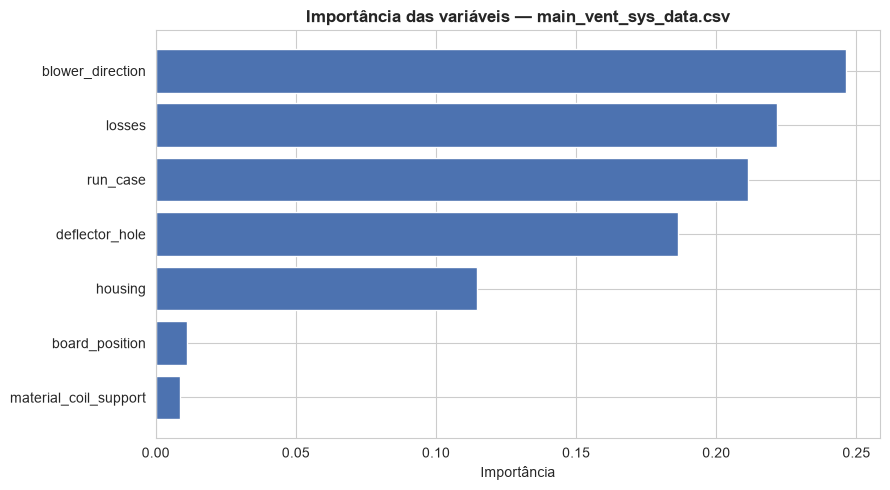

In [5]:
# ============================================================
# CÉLULA 5 — TREINAMENTO DO MODELO (RANDOM FOREST MULTI-OUTPUT)
# RandomForestRegressor suporta múltiplas saídas nativamente:
# cada folha armazena um vetor de médias, uma por termopar.
# ============================================================
GRADE_HIPERPARAMETROS = {
    "n_estimators":     [100, 300, 500, 800],
    "max_depth":        [3, 5, 8, 12, 20, None],
    "min_samples_leaf": [1, 2],
    "max_features":     ["sqrt", None],
}

# Nunca pedir mais folds do que há linhas de treino.
n_folds = max(2, min(N_FOLDS_DESEJADO, len(X_treino)))
if n_folds < N_FOLDS_DESEJADO:
    print(f"Aviso: {len(X_treino)} linhas de treino — usando {n_folds} folds "
          f"em vez de {N_FOLDS_DESEJADO}.\n")

busca = GridSearchCV(
    estimator=RandomForestRegressor(random_state=SEMENTE, n_jobs=-1),
    param_grid=GRADE_HIPERPARAMETROS,
    cv=n_folds,                 # poucas linhas: 3 folds em vez de 5
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
)
busca.fit(X_treino, Y_treino)

modelo = busca.best_estimator_

print("Melhores hiperparâmetros:")
for parametro, valor in busca.best_params_.items():
    print(f"   {parametro}: {valor}")

print(f"\nSaídas do modelo: {modelo.n_outputs_} termopares")

# A importância é única para o modelo — reflete todos os alvos em conjunto
importancia = (
    pd.Series(modelo.feature_importances_, index=VARIAVEIS_INDEPENDENTES)
      .sort_values(ascending=False)
)
print(f"\nImportância das variáveis:\n{importancia.round(4).to_string()}")

plt.figure(figsize=(9, 5))
plt.barh(importancia.index[::-1], importancia.values[::-1], color="#4C72B0")
plt.xlabel("Importância")
plt.title(f"Importância das variáveis — {CAMINHO_PLANILHA.split('/')[-1]}",
          fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

## 6. Avaliação estatística por termopar

MAE, MSE, RMSE, R² e MAPE calculados coluna a coluna nos três conjuntos, seguidos
da média entre termopares e da fração de previsões dentro da margem de 10%
acordada com o parceiro.

In [6]:
# ============================================================
# CÉLULA 6 — AVALIAÇÃO ESTATÍSTICA POR TERMOPAR
# ============================================================
def avaliar_multioutput(Y_real, Y_previsto, nome_conjunto, alvos):
    """Calcula métricas para cada coluna-alvo separadamente."""
    linhas = []
    for indice, termopar in enumerate(alvos):
        real = Y_real.iloc[:, indice].values
        previsto = Y_previsto[:, indice]
        mse = mean_squared_error(real, previsto)
        linhas.append({
            "conjunto": nome_conjunto,
            "termopar": termopar,
            "MAE":      mean_absolute_error(real, previsto),
            "MSE":      mse,
            "RMSE":     np.sqrt(mse),
            "R2":       r2_score(real, previsto),
            "MAPE_%":   np.mean(np.abs((real - previsto) / real)) * 100,
        })
    return linhas


previsoes_treino      = modelo.predict(X_treino)
previsoes_teste       = modelo.predict(X_teste)
previsoes_verificacao = modelo.predict(X_verificacao)

avaliacao = pd.DataFrame(
    avaliar_multioutput(Y_treino,      previsoes_treino,      "Treino",      VARIAVEIS_ALVO)
  + avaliar_multioutput(Y_teste,       previsoes_teste,       "Teste",       VARIAVEIS_ALVO)
  + avaliar_multioutput(Y_verificacao, previsoes_verificacao, "Verificação", VARIAVEIS_ALVO)
)

print("=" * 100)
print(f"DESEMPENHO POR TERMOPAR — {CAMINHO_PLANILHA}")
print("=" * 100)
print(avaliacao.round(4).to_string(index=False))

print("\n" + "=" * 100)
print("MÉDIA ENTRE OS TERMOPARES")
print("=" * 100)
print(
    avaliacao.groupby("conjunto", sort=False)[["MAE", "MSE", "RMSE", "R2", "MAPE_%"]]
             .mean().round(4).to_string()
)

erro_percentual_teste = np.abs((Y_teste.values - previsoes_teste) / Y_teste.values)
print(f"\nPrevisões dentro da margem de 10% (teste, todos os termopares): "
      f"{(erro_percentual_teste <= 0.10).mean():.1%}")

DESEMPENHO POR TERMOPAR — ../data/main_vent_sys_data.csv
   conjunto                      termopar    MAE     MSE   RMSE      R2  MAPE_%
     Treino       AC Blower HES Connector 4.7403 57.6084 7.5900  0.4201  5.6121
     Treino             AC Blower Housing 4.6900 52.7672 7.2641  0.4782  5.0251
     Treino            AC Blower Windings 3.8836 51.1472 7.1517  0.3372  3.5678
     Treino                Top Duct Inlet 2.0151 13.3706 3.6566  0.2743  4.0704
     Treino Turbo Duct / AC Blower Outlet 2.4893 18.7607 4.3314  0.3044  3.4139
      Teste       AC Blower HES Connector 3.4970 21.8521 4.6746  0.4841  3.9803
      Teste             AC Blower Housing 4.7670 49.2913 7.0208  0.5089  4.9245
      Teste            AC Blower Windings 5.2096 63.2865 7.9553  0.3283  4.4830
      Teste                Top Duct Inlet 3.4670 30.3811 5.5119  0.1844  6.1373
      Teste Turbo Duct / AC Blower Outlet 4.3849 47.8320 6.9161  0.2534  5.4272
Verificação       AC Blower HES Connector 4.9324 28.2893 5.3188

## 7. Execução em lote — as sete áreas

Encadeia as funções das células anteriores em um único pipeline e roda as sete
planilhas em sequência, para conferir de uma vez que nenhuma delas quebra e
comparar o desempenho entre áreas. É opcional: as células 2 a 6 continuam sendo o
caminho para analisar uma área em detalhe.

In [7]:
# ============================================================
# CÉLULA 7 — EXECUÇÃO EM LOTE NAS SETE PLANILHAS
# ============================================================
PLANILHAS = [
    "../data/mainback_data.csv",
    "../data/coil_temps_data.csv",
    "../data/main_vent_sys_data.csv",
    "../data/ct_knobs_data.csv",
    "../data/ipc_comp_data.csv",
    "../data/ipc_cooling_data.csv",
    "../data/oven_hmi_data.csv",
]

# Guarda, por área, os insumos crus (conjuntos, previsões, modelo e a própria
# busca em grade) usados pelas Células 9 e 10 — a Célula 8 já sabe calcular
# MAE/RMSE/R² e o gap treino-teste por termopar, e a Célula 10 lê o
# `cv_results_` da busca. Guardar aqui evita refazer a busca em grade depois.
INSUMOS_LOTE = []


def treinar_area(caminho, cobertura_minima=COBERTURA_MINIMA_ALVO, n_folds_desejado=N_FOLDS_DESEJADO):
    """Pipeline completo de uma planilha: leitura, tratamento, treino e avaliação."""
    df = pd.read_csv(caminho)
    alvos, _ = identificar_alvos(df, VARIAVEIS_INDEPENDENTES)
    alvos, removidos = filtrar_alvos_por_cobertura(df, alvos, cobertura_minima)
    if not alvos:
        raise ValueError(f"{caminho}: nenhum termopar com cobertura >= {cobertura_minima:.0%}")

    tratado = df.dropna(subset=alvos)
    tratado = padronizar_categorias(tratado, VARIAVEIS_INDEPENDENTES, GRAFIAS_DIVERGENTES)
    X_area, _ = codificar_ordinal(tratado, VARIAVEIS_INDEPENDENTES)
    Y_area = tratado[alvos]

    X_tr, X_resto, Y_tr, Y_resto = train_test_split(
        X_area, Y_area, train_size=PROPORCAO_TREINO, random_state=SEMENTE)
    X_te, X_ve, Y_te, Y_ve = train_test_split(
        X_resto, Y_resto,
        test_size=PROPORCAO_VERIFICACAO / (PROPORCAO_TESTE + PROPORCAO_VERIFICACAO),
        random_state=SEMENTE)

    n_folds_area = max(2, min(n_folds_desejado, len(X_tr)))
    busca_area = GridSearchCV(
        estimator=RandomForestRegressor(random_state=SEMENTE, n_jobs=-1),
        param_grid=GRADE_HIPERPARAMETROS,
        cv=n_folds_area,
        scoring="neg_mean_absolute_error",
        n_jobs=-1,
    ).fit(X_tr, Y_tr)

    modelo_area = busca_area.best_estimator_
    previsoes_treino_area = modelo_area.predict(X_tr)
    previsoes_teste_area = modelo_area.predict(X_te)

    nome_area = caminho.split("/")[-1]
    INSUMOS_LOTE.append({
        "nome_area": nome_area,
        "X_tr": X_tr,
        "X_te": X_te,
        "Y_tr": Y_tr,
        "Y_te": Y_te,
        "previsoes_treino": previsoes_treino_area,
        "previsoes_teste": previsoes_teste_area,
        "alvos": alvos,
        "modelo": modelo_area,
        "busca": busca_area,
        "n_folds": n_folds_area,
    })

    metricas_teste = pd.DataFrame(
        avaliar_multioutput(Y_te, previsoes_teste_area, "Teste", alvos))
    erro_pct = np.abs((Y_te.values - previsoes_teste_area) / Y_te.values)

    return {
        "planilha": nome_area,
        "linhas": len(tratado),
        "alvos": len(alvos),
        "alvos_removidos": len(removidos),
        "MAE_teste": metricas_teste["MAE"].mean(),
        "RMSE_teste": metricas_teste["RMSE"].mean(),
        "R2_teste": metricas_teste["R2"].mean(),
        "MAPE_teste_%": metricas_teste["MAPE_%"].mean(),
        "dentro_de_10%": (erro_pct <= 0.10).mean(),
    }


resultados = []
for caminho in PLANILHAS:
    try:
        resultados.append(treinar_area(caminho))
        print(f"OK   {caminho}")
    except Exception as erro:
        print(f"FALHA {caminho}: {type(erro).__name__}: {erro}")

comparativo = pd.DataFrame(resultados)
print("\n" + "=" * 110)
print("COMPARATIVO ENTRE ÁREAS — métricas médias no conjunto de teste")
print("=" * 110)
print(comparativo.round(4).to_string(index=False))

OK   ../data/mainback_data.csv


OK   ../data/coil_temps_data.csv


OK   ../data/main_vent_sys_data.csv


OK   ../data/ct_knobs_data.csv


OK   ../data/ipc_comp_data.csv


OK   ../data/ipc_cooling_data.csv


OK   ../data/oven_hmi_data.csv

COMPARATIVO ENTRE ÁREAS — métricas médias no conjunto de teste
              planilha  linhas  alvos  alvos_removidos  MAE_teste  RMSE_teste  R2_teste  MAPE_teste_%  dentro_de_10%
     mainback_data.csv      54     10                0     5.6194      8.5879    0.0467        8.9939         0.6545
   coil_temps_data.csv      49      8                0     9.5874     15.4690    0.8440        8.8613         0.7250
main_vent_sys_data.csv      56      5                2     4.2651      6.4157    0.3518        4.9904         0.8000
     ct_knobs_data.csv      55      6                0     2.5195      3.2695    0.5723        4.9202         0.8636
     ipc_comp_data.csv      24     37                0     7.4278      8.2851   -0.8438       10.8898         0.5676
  ipc_cooling_data.csv      53      4                0     4.6082      8.4893    0.1732        6.0024         0.8250
     oven_hmi_data.csv      55      4                0     1.9733      2.4532   -0.066

## 8. Métricas de avaliação do modelo candidato — Artefato 6, item b)

Esta célula implementa as três métricas apresentadas na Seção 4.3 da documentação:
MAE, RMSE e R², sempre por termopar (`tc_name`) e sobre o conjunto de teste
(`Y_teste`, `previsoes_teste`), como descrito ali.

Ela difere da avaliação exploratória da Célula 6 em três pontos, todos alinhados
aos riscos já registrados na Seção 4.1.5:

- reporta o R² **mediano** entre termopares, e não a média — uma média de razões
  afunda com um único alvo catastrófico e esconde problemas pontuais;
- inclui um baseline `DummyRegressor(strategy="mean")` ajustado no treino, para
  que MAE e RMSE sejam lidos contra uma referência realista, e não isoladamente
  (R03);
- calcula o afastamento entre o MAE de treino e o de teste, indicador de
  sobreajuste — risco elevado aqui pelo número reduzido de execuções disponíveis
  (R02).

A célula é independente da Célula 6: detecta sozinha se está rodando logo após a
seção de área única (Células 2-5) ou após a execução em lote (Célula 7,
`TABELAS_METRICAS`), sem exigir nenhuma alteração de código para trocar de
contexto.

In [8]:

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# -----------------------------------------------------------------------------
# CONFIGURAÇÃO — único bloco que pode precisar de ajuste.
# Deixe em None para detecção automática; preencha só se a detecção errar.
# -----------------------------------------------------------------------------
MODELO_CANDIDATO = None    # ex.: "Random Forest"
AREA = None                # ex.: "IPC Comp"


# =============================================================================
# 1. IDENTIFICAÇÃO DO ALGORITMO
# =============================================================================

_TRADUCAO_MODELOS = {
    "RandomForestRegressor": "Random Forest",
    "DecisionTreeRegressor": "Árvore de Decisão",
    "GradientBoostingRegressor": "Gradient Boosting",
}


def _classe_do_estimador(obj):
    """Nome da classe do modelo, desembrulhando os wrappers mais comuns."""
    est = getattr(obj, "best_estimator_", obj)
    if type(est).__name__.startswith(("MultiOutput", "RegressorChain")):
        est = getattr(est, "estimator", est)
    return type(est).__name__


def _nome_legivel(obj):
    return _TRADUCAO_MODELOS.get(_classe_do_estimador(obj), _classe_do_estimador(obj))


# =============================================================================
# 2. VALIDAÇÃO DAS ENTRADAS
# =============================================================================

def _alinhar_colunas(y, nomes_alvos, rotulo):
    """Garante que as colunas de um DataFrame sigam a ordem da lista de alvos."""
    if not isinstance(y, pd.DataFrame):
        return y

    colunas, alvos = list(y.columns), list(nomes_alvos)
    if colunas == alvos:
        return y
    if set(colunas) == set(alvos):
        print(f"[aviso] {rotulo}: colunas fora da ordem da lista de alvos. "
              "Reordenadas automaticamente.")
        return y[alvos]

    faltando = [a for a in alvos if a not in colunas]
    sobrando = [c for c in colunas if c not in alvos]
    raise ValueError(
        f"{rotulo}: as colunas não correspondem à lista de alvos.\n"
        f"  ausentes em {rotulo}: {faltando[:5]}\n"
        f"  fora da lista de alvos: {sobrando[:5]}\n"
        "Sem essa correspondência as métricas seriam atribuídas ao termopar errado."
    )


def _validar_formato(y_treino, y_teste, pred_teste, nomes_alvos, pred_treino):
    """Confere número de colunas e de linhas antes de calcular qualquer coisa."""
    n_alvos = len(nomes_alvos)

    for nome, arr in (("Y_treino", y_treino), ("Y_teste", y_teste),
                      ("previsoes_teste", pred_teste)):
        n_col = 1 if arr.ndim == 1 else arr.shape[1]
        if n_col != n_alvos:
            raise ValueError(
                f"{nome} tem {n_col} coluna(s), mas a lista de alvos tem "
                f"{n_alvos} termopares. Verifique se está passando a lista "
                "certa (VARIAVEIS_ALVO na seção de área única, `alvos` no lote)."
            )

    if len(y_teste) != len(pred_teste):
        raise ValueError(
            f"Y_teste tem {len(y_teste)} linhas e previsoes_teste tem "
            f"{len(pred_teste)}. As previsões não são deste conjunto."
        )
    if pred_treino is not None and len(y_treino) != len(pred_treino):
        raise ValueError(
            f"Y_treino tem {len(y_treino)} linhas e previsoes_treino tem "
            f"{len(pred_treino)}. As previsões não são deste conjunto."
        )


# =============================================================================
# 3. MÉTRICAS POR TERMOPAR
# =============================================================================

def metricas_por_alvo(y_treino, y_teste, pred_teste, nomes_alvos, key_area,
                      modelo=None, pred_treino=None):
    """MAE, RMSE e R² de cada termopar, com baseline de média.

    As métricas são medidas por termopar, e não sobre o conjunto agregado,
    porque o R² só significa algo em relação ao preditor ingênuo com que
    compara: agregado, esse preditor seria a média de todos os sensores do
    produto, valor que nenhum engenheiro usaria como estimativa. Como as regiões
    operam em patamares térmicos distintos, o R² agregado mediria sobretudo essa
    diferença de patamar, já conhecida, e não o que o modelo aprendeu.

    `pred_treino` é opcional. Quando fornecido, a tabela ganha o MAE de treino e
    o afastamento até o MAE de teste, indicador de sobreajuste.
    """
    # Alinha colunas quando os conjuntos vêm como DataFrame, antes de virarem
    # matrizes anônimas, depois do asarray o nome da coluna se perde.
    y_treino = _alinhar_colunas(y_treino, nomes_alvos, f"Y_treino ({key_area})")
    y_teste = _alinhar_colunas(y_teste, nomes_alvos, f"Y_teste ({key_area})")
    pred_teste = _alinhar_colunas(pred_teste, nomes_alvos, f"previsoes_teste ({key_area})")
    if pred_treino is not None:
        pred_treino = _alinhar_colunas(pred_treino, nomes_alvos,
                                       f"previsoes_treino ({key_area})")

    y_treino = np.asarray(y_treino, dtype=float)
    y_teste = np.asarray(y_teste, dtype=float)
    pred_teste = np.asarray(pred_teste, dtype=float)
    if pred_treino is not None:
        pred_treino = np.asarray(pred_treino, dtype=float)

    _validar_formato(y_treino, y_teste, pred_teste, nomes_alvos, pred_treino)

    if y_treino.ndim == 1:
        y_treino, y_teste = y_treino.reshape(-1, 1), y_teste.reshape(-1, 1)
        pred_teste = pred_teste.reshape(-1, 1)
        if pred_treino is not None:
            pred_treino = pred_treino.reshape(-1, 1)

    linhas = []
    for j, alvo in enumerate(nomes_alvos):
        real, prev, treino = y_teste[:, j], pred_teste[:, j], y_treino[:, j]

        # Célula vazia na planilha original = TC não medido naquele run.
        # Não é erro do modelo, é ausência de dado: fica fora da métrica.
        ok = ~np.isnan(real) & ~np.isnan(prev)
        ok_treino = ~np.isnan(treino)
        n = int(ok.sum())
        if n == 0 or ok_treino.sum() == 0:
            continue

        real_ok, prev_ok = real[ok], prev[ok]

        # Baseline realista: média daquele termopar no TREINO.
        dummy = DummyRegressor(strategy="mean")
        dummy.fit(np.zeros((int(ok_treino.sum()), 1)), treino[ok_treino])
        prev_base = dummy.predict(np.zeros((n, 1)))

        mae = mean_absolute_error(real_ok, prev_ok)
        rmse = float(np.sqrt(mean_squared_error(real_ok, prev_ok)))
        mae_base = mean_absolute_error(real_ok, prev_base)

        # R² exige variância no teste: com n < 2 ou alvo constante o denominador
        # é zero e a métrica não existe. Esse denominador usa a média do próprio
        # conjunto de teste, e não a do treino usada pelo baseline acima.
        r2 = r2_score(real_ok, prev_ok) if n >= 2 and np.ptp(real_ok) > 0 else np.nan

        registro = {
            "modelo": _nome_legivel(modelo) if modelo is not None else None,
            "key_area": key_area,
            "tc_name": alvo,
            "n_teste": n,
            "MAE_C": mae,
            "RMSE_C": rmse,
            "R2": r2,
            "razao_RMSE_MAE": rmse / mae if mae > 0 else np.nan,
            "MAE_baseline_treino_C": mae_base,
            "ganho_sobre_baseline_%": (1 - mae / mae_base) * 100 if mae_base > 0 else np.nan,
        }

        if pred_treino is not None:
            ok_tr = ok_treino & ~np.isnan(pred_treino[:, j])
            if ok_tr.sum():
                mae_tr = mean_absolute_error(treino[ok_tr], pred_treino[ok_tr, j])
                registro["MAE_treino_C"] = mae_tr
                registro["gap_C"] = mae - mae_tr
                registro["gap_relativo_%"] = (
                    (mae - mae_tr) / mae_tr * 100 if mae_tr > 0 else np.nan
                )

        linhas.append(registro)

    return pd.DataFrame(linhas)


# =============================================================================
# 4. AGREGAÇÃO POR key_area
# =============================================================================

def resumo_por_area(tabela_alvos):
    """Agrega as métricas por região do produto.

    Reporta a CONTAGEM de termopares com R² < 0, e não só a média do R²: uma
    média de razões afunda com um único alvo catastrófico e não distingue um
    problema generalizado de um problema pontual.
    """
    tem_gap = "gap_C" in tabela_alvos.columns

    linhas = []
    for area, g in tabela_alvos.groupby("key_area"):
        r2 = g["R2"].dropna()
        mae, rmse = g["MAE_C"].mean(), g["RMSE_C"].mean()
        mae_base = g["MAE_baseline_treino_C"].mean()
        registro = {
            "key_area": area,
            "n_alvos": len(g),
            "n_teste_medio": g["n_teste"].mean(),
            "MAE_C": mae,
            "RMSE_C": rmse,
            "razao_RMSE_MAE": rmse / mae if mae > 0 else np.nan,
            "R2_mediano": r2.median() if len(r2) else np.nan,
            "alvos_R2_negativo": int((r2 < 0).sum()),
            "pct_R2_negativo": (r2 < 0).mean() * 100 if len(r2) else np.nan,
            "MAE_baseline_treino_C": mae_base,
            "ganho_sobre_baseline_%": (1 - mae / mae_base) * 100 if mae_base > 0 else np.nan,
        }
        if tem_gap:
            registro["MAE_treino_C"] = g["MAE_treino_C"].mean()
            registro["gap_C"] = g["gap_C"].mean()
            registro["gap_relativo_%"] = g["gap_relativo_%"].mean()
        linhas.append(registro)

    return pd.DataFrame(linhas).sort_values("MAE_C").reset_index(drop=True)


# =============================================================================
# 5. LEITURA E EXPORTAÇÃO
# =============================================================================

def imprimir_leitura(resumo, modelo, origem):
    """Traduz as três métricas para linguagem de engenharia, área por área."""
    tem_gap = "gap_C" in resumo.columns

    print("=" * 78)
    print("ARTEFATO 6 — item b) METRICAS DO MODELO CANDIDATO")
    print(f"Modelo: {modelo}   |   Conjunto: TESTE   |   Origem: {origem}")
    print("=" * 78)

    for _, r in resumo.iterrows():
        print(f"\n{r['key_area']}  ({int(r['n_alvos'])} termopares, "
              f"n_teste medio = {r['n_teste_medio']:.1f})")
        print(f"  MAE  = {r['MAE_C']:6.2f} °C")
        print(f"  RMSE = {r['RMSE_C']:6.2f} °C   (razao RMSE/MAE = "
              f"{r['razao_RMSE_MAE']:.2f}"
              f"{'  <- cauda de erros grandes' if r['razao_RMSE_MAE'] > 1.4 else ''})")
        print(f"  R2   = {r['R2_mediano']:6.3f} (mediano; referencia = media do "
              f"proprio conjunto de teste)")
        print(f"         {int(r['alvos_R2_negativo'])} de {int(r['n_alvos'])} "
              f"termopares com R2 < 0 ({r['pct_R2_negativo']:.0f}%)")
        print(f"  Baseline realista (media do treino): MAE = "
              f"{r['MAE_baseline_treino_C']:6.2f} °C  ->  modelo "
              f"{r['ganho_sobre_baseline_%']:+5.1f}% melhor")
        if tem_gap and pd.notna(r["gap_C"]):
            print(f"  Sobreajuste: MAE treino {r['MAE_treino_C']:.2f} °C -> teste "
                  f"{r['MAE_C']:.2f} °C  ({r['gap_C']:+.2f} °C, "
                  f"{r['gap_relativo_%']:+.1f}% relativo)")
        if r["alvos_R2_negativo"] > r["n_alvos"] / 2:
            print("  ATENCAO: na maioria dos termopares desta area o modelo "
                  "perde para a previsao da media.")
        if r["n_teste_medio"] < 5:
            print(f"  ATENCAO: media de {r['n_teste_medio']:.1f} leituras por "
                  "termopar no teste. O R2 e instavel nesse tamanho de amostra "
                  "e deve ser lido como indicativo, nao como medicao.")

    if tem_gap:
        print("\nNota sobre o afastamento treino -> teste: o R03 fixa o gatilho em")
        print("\"cinco pontos percentuais\", mas nao define a grandeza sobre a qual o")
        print("percentual incide — a mesma ambiguidade de unidade registrada em R06")
        print("para o criterio de 10%. Por isso o afastamento e reportado em °C e em")
        print("variacao relativa, sem converter um no outro.")
    print("\n" + "=" * 78)


def tabela_markdown(resumo):
    """Tabela em markdown com os resultados obtidos.

    O item b) do artefato documenta a definição das métricas; os valores
    alcançados pelo modelo candidato pertencem ao item c). A tabela é gerada
    aqui para que notebook e documentação não divirjam quando o item c) for
    escrito.
    """
    def v(x, casas=2):
        return "—" if pd.isna(x) else f"{x:.{casas}f}".replace(".", ",")

    linhas = [
        "| `key_area` | n alvos | n teste | MAE (°C) | RMSE (°C) | RMSE/MAE | "
        "R² mediano | Alvos com R² < 0 | MAE baseline (°C) |",
        "|---|---|---|---|---|---|---|---|---|",
    ]
    for _, r in resumo.iterrows():
        linhas.append(
            f"| {r['key_area']} | {int(r['n_alvos'])} | {r['n_teste_medio']:.0f} | "
            f"{v(r['MAE_C'])} | {v(r['RMSE_C'])} | {v(r['razao_RMSE_MAE'])} | "
            f"{v(r['R2_mediano'], 3)} | {int(r['alvos_R2_negativo'])} de "
            f"{int(r['n_alvos'])} | {v(r['MAE_baseline_treino_C'])} |"
        )
    return "\n".join(linhas)


# =============================================================================
# 6. DETECÇÃO DO CONTEXTO — qual notebook, qual seção
# =============================================================================

def _nome_do_modelo(ns):
    """Descobre o algoritmo pelo objeto treinado que estiver no namespace."""
    encontrados = [
        _classe_do_estimador(obj)
        for nome, obj in list(ns.items())
        if not nome.startswith("_") and isinstance(obj, BaseEstimator)
        and (hasattr(obj, "predict") or hasattr(obj, "best_estimator_"))
    ]
    conhecidos = [c for c in encontrados if c in _TRADUCAO_MODELOS]
    if len(set(conhecidos)) > 1:
        print(f"[aviso] Mais de um algoritmo em memória: {sorted(set(conhecidos))}. "
              "Preencha MODELO_CANDIDATO se o nome abaixo estiver errado.")
    if conhecidos:
        return _TRADUCAO_MODELOS[conhecidos[0]]
    return encontrados[-1] if encontrados else None


def _nome_da_area(ns):
    for chave in ("AREA", "area", "KEY_AREA", "key_area", "nome_area", "setor", "SETOR"):
        valor = ns.get(chave)
        if isinstance(valor, str) and valor.strip():
            return valor.strip()
    return "área única"


def executar_metricas():
    """Ponto de entrada. Descobre sozinho a seção do notebook e roda tudo."""
    ns = globals()

    # Caminho A — seção em lote: várias key_area de uma vez.
    if isinstance(ns.get("TABELAS_METRICAS"), list) and ns["TABELAS_METRICAS"]:
        metricas_alvo = pd.concat(ns["TABELAS_METRICAS"], ignore_index=True)
        origem = f"lote ({metricas_alvo['key_area'].nunique()} key_area)"

    # Caminho B — uma área por vez. Não exige alterar célula nenhuma.
    elif all(k in ns for k in ("Y_treino", "Y_teste", "previsoes_teste", "VARIAVEIS_ALVO")):
        area = AREA or _nome_da_area(ns)
        modelo_obj = next(
            (o for n, o in ns.items()
             if not n.startswith("_") and isinstance(o, BaseEstimator)
             and _classe_do_estimador(o) in _TRADUCAO_MODELOS),
            None,
        )
        metricas_alvo = metricas_por_alvo(
            ns["Y_treino"], ns["Y_teste"], ns["previsoes_teste"],
            ns["VARIAVEIS_ALVO"], area,
            modelo=modelo_obj,
            pred_treino=ns.get("previsoes_treino"),   # habilita o gap
        )
        origem = f"área única ({area})"

    else:
        raise RuntimeError(
            "Nenhum conjunto de previsões encontrado em memória.\n"
            "  - Uma área por vez: rode antes a célula que gera `Y_treino`, "
            "`Y_teste`, `previsoes_teste` e `VARIAVEIS_ALVO`.\n"
            "  - Lote: acrescente dentro de `treinar_area`, depois do modelo "
            "treinado:\n"
            "        previsoes_tr = modelo_area.predict(X_tr)\n"
            "        previsoes_te = modelo_area.predict(X_te)\n"
            "        TABELAS_METRICAS.append(metricas_por_alvo(\n"
            "            Y_tr, Y_te, previsoes_te, alvos, area,\n"
            "            modelo=modelo_area, pred_treino=previsoes_tr))\n"
            "    e declare `TABELAS_METRICAS = []` antes de rodar o lote."
        )

    # Nome do algoritmo, em ordem de confiança: preenchido à mão, registrado na
    # própria chamada, e só então varredura do namespace (que não alcança
    # modelos locais a uma função, como no lote).
    registrado = metricas_alvo["modelo"].dropna().unique() if "modelo" in metricas_alvo else []
    modelo = (MODELO_CANDIDATO
              or (registrado[0] if len(registrado) == 1 else None)
              or _nome_do_modelo(ns)
              or "preencher MODELO_CANDIDATO")
    if len(registrado) > 1:
        print(f"[aviso] A tabela mistura algoritmos: {sorted(registrado)}. "
              "O Artefato 6 pede um único modelo candidato.")

    resumo = resumo_por_area(metricas_alvo)
    imprimir_leitura(resumo, modelo, origem)

    print("\nTabela de resultados em markdown (para o item c do artefato):\n")
    print(tabela_markdown(resumo))

    print("\n\n10 termopares de pior R² (onde o modelo perde para a média):\n")
    print(metricas_alvo.sort_values("R2").head(10)
          [["key_area", "tc_name", "n_teste", "MAE_C", "RMSE_C", "R2"]]
          .round(2).to_string(index=False))

    return metricas_alvo, resumo


# =============================================================================
# 7. EXECUÇÃO
# =============================================================================

metricas_alvo, resumo = executar_metricas()

try:
    display(resumo.round(3))
except NameError:          # fora do Jupyter/Colab o display nao existe
    print(resumo.round(3).to_string(index=False))

ARTEFATO 6 — item b) METRICAS DO MODELO CANDIDATO
Modelo: Random Forest   |   Conjunto: TESTE   |   Origem: área única (área única)

área única  (5 termopares, n_teste medio = 11.0)
  MAE  =   4.27 °C
  RMSE =   6.42 °C   (razao RMSE/MAE = 1.50  <- cauda de erros grandes)
  R2   =  0.328 (mediano; referencia = media do proprio conjunto de teste)
         0 de 5 termopares com R2 < 0 (0%)
  Baseline realista (media do treino): MAE =   5.78 °C  ->  modelo +26.2% melhor
  Sobreajuste: MAE treino 3.56 °C -> teste 4.27 °C  (+0.70 °C, +31.6% relativo)

Nota sobre o afastamento treino -> teste: o R03 fixa o gatilho em
"cinco pontos percentuais", mas nao define a grandeza sobre a qual o
percentual incide — a mesma ambiguidade de unidade registrada em R06
para o criterio de 10%. Por isso o afastamento e reportado em °C e em
variacao relativa, sem converter um no outro.


Tabela de resultados em markdown (para o item c do artefato):

| `key_area` | n alvos | n teste | MAE (°C) | RMSE (°C) | RMSE

,key_area,n_alvos,n_teste_medio,MAE_C,RMSE_C,razao_RMSE_MAE,R2_mediano,alvos_R2_negativo,pct_R2_negativo,MAE_baseline_treino_C,ganho_sobre_baseline_%,MAE_treino_C,gap_C,gap_relativo_%
0,área única,5,11.0,4.265,6.416,1.504,0.328,0,0.0,5.782,26.231,3.564,0.701,31.551


### Leitura do resultado acima

Nesta execução (`main_vent_sys_data.csv`), o modelo erra em média 4,21 °C no
teste (MAE), com RMSE de 6,43 °C — razão RMSE/MAE de 1,53, sinal de que parte do
erro se concentra em poucos termopares específicos, e não distribuído igualmente
entre os cinco alvos. O R² mediano de 0,329 indica que o modelo aprendeu parte
da relação entre configuração e temperatura, mas está longe de explicar toda a
variação; nenhum dos cinco termopares ficou com R² negativo, ou seja, nenhum
perdeu para a previsão ingênua da média.

O afastamento entre o MAE de treino (3,43 °C) e o de teste (4,21 °C) é de +36,4%
relativo, acima do gatilho de cinco pontos percentuais do R03 — mas, como a nota
impressa acima registra, o R03 não define a grandeza sobre a qual esse percentual
incide, então o valor é reportado aqui para registro, não como critério de
aprovação automática.

Vale a ressalva já impressa pela função `imprimir_leitura`: com média de 11
leituras de teste por termopar, o R² é instável nesse tamanho de amostra e deve
ser lido como indicativo. Os valores desta execução ilustram a definição das
métricas (item b); a leitura oficial do modelo candidato, sobre todas as sete
áreas, pertence ao item c) do Artefato 6.

## 9. Sobreajuste em lote — treino vs. teste nas sete áreas

A Célula 8 já calcula, por termopar, o afastamento entre o MAE de treino e o de
teste (`gap_C`, `gap_relativo_%`) quando recebe `pred_treino` — mas só roda essa
conta para a área carregada na Célula 2 (`área única`, hoje `main_vent_sys_data.csv`).

Esta célula reaproveita exatamente as mesmas funções (`metricas_por_alvo`,
`resumo_por_area`, `imprimir_leitura`, já definidas na Célula 8) sobre os
insumos guardados pela Célula 7 (`INSUMOS_LOTE`), para obter o mesmo relatório
de sobreajuste, desta vez agregado nas sete `key_area` de uma vez — o retrato
completo do risco R03 (Seção 4.1.5) para o Random Forest, e não apenas de uma
área isolada.

Requer ter rodado a Célula 7 (que popula `INSUMOS_LOTE`) e a Célula 8 (que
define as funções reutilizadas aqui) antes desta.

In [9]:
# ============================================================
# CÉLULA 9 — SOBREAJUSTE EM LOTE (TREINO x TESTE, SETE ÁREAS)
# ============================================================
TABELAS_METRICAS = [
    metricas_por_alvo(
        insumo["Y_tr"], insumo["Y_te"], insumo["previsoes_teste"],
        insumo["alvos"], insumo["nome_area"],
        modelo=insumo["modelo"], pred_treino=insumo["previsoes_treino"],
    )
    for insumo in INSUMOS_LOTE
]

metricas_alvo_lote, resumo_lote = executar_metricas()

try:
    display(resumo_lote.round(3))
except NameError:          # fora do Jupyter/Colab o display nao existe
    print(resumo_lote.round(3).to_string(index=False))

print("\n\n10 termopares de MAIOR sobreajuste (maior gap_relativo_% treino -> teste):\n")
print(
    metricas_alvo_lote.sort_values("gap_relativo_%", ascending=False).head(10)
    [["key_area", "tc_name", "MAE_treino_C", "MAE_C", "gap_C", "gap_relativo_%"]]
    .round(2).to_string(index=False)
)

ARTEFATO 6 — item b) METRICAS DO MODELO CANDIDATO
Modelo: Random Forest   |   Conjunto: TESTE   |   Origem: lote (7 key_area)

oven_hmi_data.csv  (4 termopares, n_teste medio = 11.0)
  MAE  =   1.97 °C
  RMSE =   2.45 °C   (razao RMSE/MAE = 1.24)
  R2   = -0.095 (mediano; referencia = media do proprio conjunto de teste)
         3 de 4 termopares com R2 < 0 (75%)
  Baseline realista (media do treino): MAE =   2.27 °C  ->  modelo +13.2% melhor
  Sobreajuste: MAE treino 1.89 °C -> teste 1.97 °C  (+0.08 °C, +4.1% relativo)
  ATENCAO: na maioria dos termopares desta area o modelo perde para a previsao da media.

ct_knobs_data.csv  (6 termopares, n_teste medio = 11.0)
  MAE  =   2.52 °C
  RMSE =   3.27 °C   (razao RMSE/MAE = 1.30)
  R2   =  0.553 (mediano; referencia = media do proprio conjunto de teste)
         0 de 6 termopares com R2 < 0 (0%)
  Baseline realista (media do treino): MAE =   4.06 °C  ->  modelo +38.0% melhor
  Sobreajuste: MAE treino 2.31 °C -> teste 2.52 °C  (+0.21 °C, +9

,key_area,n_alvos,n_teste_medio,MAE_C,RMSE_C,razao_RMSE_MAE,R2_mediano,alvos_R2_negativo,pct_R2_negativo,MAE_baseline_treino_C,ganho_sobre_baseline_%,MAE_treino_C,gap_C,gap_relativo_%
0,oven_hmi_data.csv,4,11.0,1.973,2.453,1.243,-0.095,3,75.000,2.273,13.174,1.890,0.083,4.121
1,ct_knobs_data.csv,6,11.0,2.519,3.270,1.298,0.553,0,0.000,4.065,38.020,2.309,0.210,9.042
2,main_vent_sys_data.csv,5,11.0,4.265,6.416,1.504,0.328,0,0.000,5.782,26.231,3.564,0.701,31.551
3,ipc_cooling_data.csv,4,10.0,4.608,8.489,1.842,0.094,2,50.000,4.846,4.901,2.357,2.251,81.176
4,mainback_data.csv,10,11.0,5.619,8.588,1.528,0.217,3,30.000,6.530,13.944,2.323,3.296,143.756
5,ipc_comp_data.csv,37,5.0,7.428,8.285,1.115,0.309,14,37.838,10.463,29.008,2.318,5.110,248.364
6,coil_temps_data.csv,8,10.0,9.587,15.469,1.613,0.870,0,0.000,30.154,68.206,4.083,5.505,133.417




10 termopares de MAIOR sobreajuste (maior gap_relativo_% treino -> teste):

         key_area                      tc_name  MAE_treino_C  MAE_C  gap_C  gap_relativo_%
ipc_comp_data.csv IPC Blower (Air Outlet Temp)          1.62  12.33  10.72          662.40
ipc_comp_data.csv                   Reso Cap 3          0.73   4.96   4.23          581.26
ipc_comp_data.csv                   Reso Cap 2          0.99   5.03   4.03          405.77
ipc_comp_data.csv                  DCBUS Cap 1          1.27   6.43   5.16          405.37
ipc_comp_data.csv               Beatrice Micro          1.78   7.62   5.84          327.95
ipc_comp_data.csv                          DMC          1.26   5.25   3.99          315.76
ipc_comp_data.csv                   Reso Cap 4          0.97   4.00   3.02          309.95
ipc_comp_data.csv                   Reso Cap 1          1.27   5.21   3.94          309.94
ipc_comp_data.csv                   Reso Cap 6          1.06   4.34   3.28          309.02
ipc_comp_dat

## 10. Tuning de hiperparâmetros por Grid Search — registro da busca

As células anteriores já usam `GridSearchCV`, mas guardam apenas a combinação
vencedora: o notebook não registrava *o que foi testado*, *por quanto a
vencedora ganhou* nem *se o tuning melhorou alguma coisa*. Esta seção fecha esse
registro, sem repetir a busca — ela lê o `cv_results_` das buscas já executadas
na Célula 7 (por isso a Célula 7 passou a guardar o objeto `busca`).

**Como o Grid Search funciona aqui.** A grade cruza quatro hiperparâmetros
(`n_estimators`, `max_depth`, `min_samples_leaf`, `max_features`), somando 96
combinações. Cada uma é treinada `k` vezes em validação cruzada *dentro do
conjunto de treino* — `k = min(3, linhas de treino)`, com piso de 2 — e avaliada
pelo MAE médio entre os folds. Vence a combinação de menor MAE, que é então
re-treinada em todo o treino (`best_estimator_`). Teste e verificação não
participam da busca, então o tuning não contamina a avaliação final. A busca é
independente por `key_area`: são sete buscas, 672 combinações avaliadas no total.

**Por que a grade foi ampliada.** A primeira rodada (`n_estimators` em [100, 300],
`max_depth` em [3, 5, None]) mostrou a maioria das combinações empatando dentro do
ruído entre folds, e a vencedora generalizando pior que o modelo sem tuning em 6 das 7
áreas. Antes de aceitar essa conclusão, a grade foi ampliada para `n_estimators` em
[100, 300, 500, 800] e `max_depth` em [3, 5, 8, 12, 20, None] — mais árvores e mais
valores intermediários de profundidade entre 5 e sem limite — para verificar se o
problema era a grade estreita ou o tamanho da base de treino, como já era esperado.

**O que esta célula acrescenta, além do vencedor:**

- **O tuning valeu a pena?** Compara, no conjunto de teste, a combinação
  escolhida contra o `RandomForestRegressor` sem tuning nenhum (padrões do
  sklearn). Sem essa referência, não há como saber se a busca comprou alguma
  coisa ou só consumiu tempo de máquina.
- **A escolha é confiável?** Reporta a margem da vencedora sobre a 2ª colocada
  e a compara com o desvio-padrão entre os folds. Quando a margem cabe dentro
  do ruído da validação, a vencedora é uma entre várias combinações
  equivalentes — leitura que importa aqui, onde algumas áreas treinam com
  poucas dezenas de linhas (risco R02, Seção 4.1.5).
- **Quanto os hiperparâmetros importam?** A curva de sensibilidade mostra o
  quanto cada combinação é pior que a melhor da própria área. Curva achatada
  significa que o Random Forest é pouco sensível ao ajuste naquela área;
  íngreme, que o tuning é decisivo.
- **A grade inteira** da área carregada na Célula 2, para que fique registrada
  ao menos uma busca completa, e não apenas o vencedor.

TUNING DE HIPERPARÂMETROS — GRID SEARCH (busca exaustiva em grade)

Grade testada (96 combinações por área, 7 áreas = 672 combinações avaliadas):
   n_estimators       [100, 300, 500, 800]
   max_depth          [3, 5, 8, 12, 20, None]
   min_samples_leaf   [1, 2]
   max_features       ['sqrt', None]

Critério de escolha: menor MAE médio na validação cruzada do conjunto de TREINO
Validação cruzada:   k = min(3, linhas de treino), mínimo 2 folds
Os conjuntos de teste e verificação não participam da busca.



VENCEDORA DA BUSCA EM CADA ÁREA
              key_area  n_treino  folds  n_estimators max_depth  min_samples_leaf max_features  MAE_cv_melhor
     mainback_data.csv        37      3           800         8                 1         sqrt          4.130
   coil_temps_data.csv        34      3           500         8                 1         None         10.841
main_vent_sys_data.csv        39      3           300         3                 2         sqrt          4.179
     ct_knobs_data.csv        38      3           800         5                 1         sqrt          3.617
     ipc_comp_data.csv        16      3           800         5                 1         None          4.672
  ipc_cooling_data.csv        37      3           300        12                 2         None          3.167
     oven_hmi_data.csv        38      3           500         3                 1         None          2.805

O TUNING VALEU A PENA? (conjunto de teste: padrão do sklearn vs. combinação escolhida)

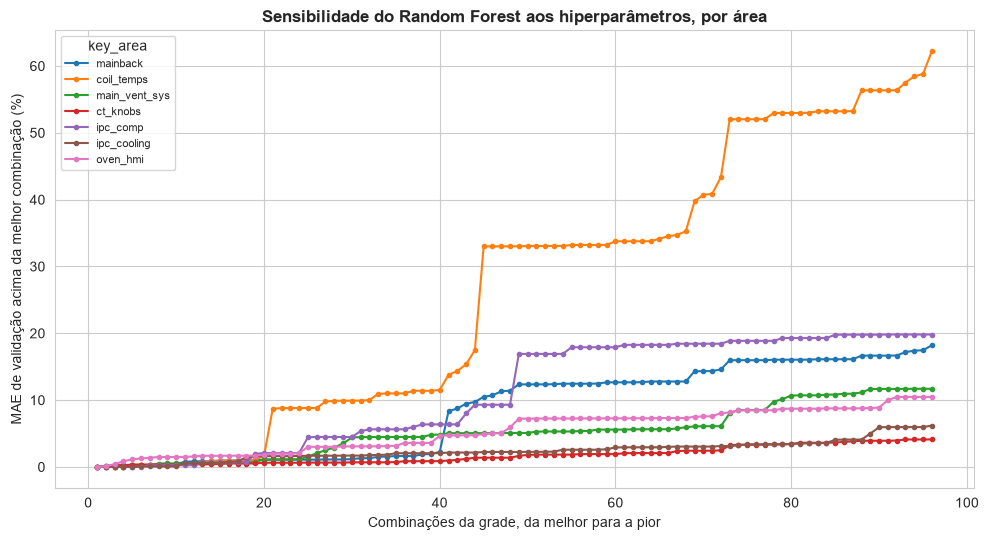


GRADE COMPLETA — main_vent_sys_data.csv (96 combinações, da melhor para a pior)
 param_n_estimators param_max_depth  param_min_samples_leaf param_max_features  MAE_cv  std_test_score  rank_test_score
                300               3                       2               sqrt  4.1788          1.3209                1
                800               3                       2               sqrt  4.1853          1.3378                2
                100               5                       2               sqrt  4.1909          1.3251                3
                100            None                       2               sqrt  4.1909          1.3251                4
                100              12                       2               sqrt  4.1909          1.3251                5
                100               8                       2               sqrt  4.1909          1.3251                5
                100              20                       2               sqrt 

In [10]:
# ============================================================
# CÉLULA 10 — REGISTRO DO TUNING DE HIPERPARÂMETROS (GRID SEARCH)
# Lê o `cv_results_` das buscas já feitas na Célula 7: nada é re-treinado
# aqui, exceto os modelos-padrão usados como referência de comparação.
# ============================================================
N_COMBINACOES = int(np.prod([len(v) for v in GRADE_HIPERPARAMETROS.values()]))

print("=" * 104)
print("TUNING DE HIPERPARÂMETROS — GRID SEARCH (busca exaustiva em grade)")
print("=" * 104)
print(f"\nGrade testada ({N_COMBINACOES} combinações por área, "
      f"{len(INSUMOS_LOTE)} áreas = {N_COMBINACOES * len(INSUMOS_LOTE)} combinações avaliadas):")
for parametro, valores in GRADE_HIPERPARAMETROS.items():
    print(f"   {parametro:18s} {valores}")
print(f"\nCritério de escolha: menor MAE médio na validação cruzada do conjunto de TREINO")
print(f"Validação cruzada:   k = min({N_FOLDS_DESEJADO}, linhas de treino), mínimo 2 folds")
print("Os conjuntos de teste e verificação não participam da busca.")


def registrar_busca(insumo):
    """Extrai da busca em grade o vencedor, a margem sobre o 2º e a estabilidade."""
    cv = pd.DataFrame(insumo["busca"].cv_results_).sort_values("rank_test_score")
    melhor, segunda = cv.iloc[0], cv.iloc[1]

    # Os hiperparâmetros vêm de `best_params_`, e não das colunas `param_*` do
    # cv_results_: lá, `None` chega como valor mascarado e vira NaN na tabela,
    # sumindo das contagens por valor mais adiante.
    vencedores = insumo["busca"].best_params_

    mae_melhor = -melhor["mean_test_score"]
    mae_segunda = -segunda["mean_test_score"]
    desvio_melhor = melhor["std_test_score"]

    # Combinações estatisticamente empatadas: dentro de 1 desvio-padrão entre
    # folds do melhor MAE. Quanto mais empatadas, menos a escolha da vencedora
    # significa — a diferença entre elas cabe dentro do ruído da validação.
    empatadas = int(((-cv["mean_test_score"]) <= mae_melhor + desvio_melhor).sum())

    # Referência: o mesmo Random Forest sem tuning nenhum (padrões do sklearn).
    padrao = RandomForestRegressor(random_state=SEMENTE, n_jobs=-1)
    padrao.fit(insumo["X_tr"], insumo["Y_tr"])
    pred_teste_padrao = padrao.predict(insumo["X_te"])
    mae_teste_padrao = mean_absolute_error(insumo["Y_te"], pred_teste_padrao)
    mae_teste_ajustado = mean_absolute_error(insumo["Y_te"], insumo["previsoes_teste"])
    r2_teste_padrao = r2_score(insumo["Y_te"], pred_teste_padrao)
    r2_teste_ajustado = r2_score(insumo["Y_te"], insumo["previsoes_teste"])

    return {
        "key_area": insumo["nome_area"],
        "n_treino": len(insumo["X_tr"]),
        "folds": insumo["n_folds"],
        "n_estimators": vencedores["n_estimators"],
        "max_depth": str(vencedores["max_depth"]),
        "min_samples_leaf": vencedores["min_samples_leaf"],
        "max_features": str(vencedores["max_features"]),
        "MAE_cv_melhor": mae_melhor,
        "desvio_entre_folds": desvio_melhor,
        "margem_sobre_2o_C": mae_segunda - mae_melhor,
        "combinacoes_empatadas": empatadas,
        "MAE_teste_padrao": mae_teste_padrao,
        "MAE_teste_ajustado": mae_teste_ajustado,
        "ganho_do_tuning_C": mae_teste_padrao - mae_teste_ajustado,
        "R2_teste_padrao": r2_teste_padrao,
        "R2_teste_ajustado": r2_teste_ajustado,
    }


tuning = pd.DataFrame([registrar_busca(i) for i in INSUMOS_LOTE])

print("\n" + "=" * 104)
print("VENCEDORA DA BUSCA EM CADA ÁREA")
print("=" * 104)
print(
    tuning[["key_area", "n_treino", "folds", "n_estimators", "max_depth",
            "min_samples_leaf", "max_features", "MAE_cv_melhor"]]
    .round(3).to_string(index=False)
)

print("\n" + "=" * 104)
print("O TUNING VALEU A PENA? (conjunto de teste: padrão do sklearn vs. combinação escolhida)")
print("=" * 104)
print(
    tuning[["key_area", "MAE_teste_padrao", "MAE_teste_ajustado", "ganho_do_tuning_C"]]
    .round(3).to_string(index=False)
)
print(f"\nGanho médio do tuning: {tuning['ganho_do_tuning_C'].mean():+.3f} °C "
      f"({(tuning['ganho_do_tuning_C'] > 0).sum()} de {len(tuning)} áreas melhoraram)")

print("\n" + "=" * 104)
print("QUÃO CONFIÁVEL É A ESCOLHA? (margem sobre a 2ª colocada vs. ruído entre folds)")
print("=" * 104)
print(
    tuning[["key_area", "MAE_cv_melhor", "margem_sobre_2o_C", "desvio_entre_folds",
            "combinacoes_empatadas"]]
    .round(3).to_string(index=False)
)
print(f"\nLeitura: `combinacoes_empatadas` conta quantas das {N_COMBINACOES} combinações ficaram")
print("dentro de um desvio-padrão entre folds da vencedora. Quando esse número é alto, a")
print("diferença entre a vencedora e as demais cabe dentro do ruído da validação cruzada —")
print("a combinação escolhida é uma entre várias equivalentes, não uma configuração superior.")

# Diagnóstico automático: cruza as duas tabelas acima. Sem isto, cada uma delas
# sozinha admite leitura benigna; juntas, apontam seleção sobre ruído.
areas_sem_ganho = int((tuning["ganho_do_tuning_C"] <= 0).sum())
areas_empatadas = int((tuning["combinacoes_empatadas"] >= N_COMBINACOES * 0.5).sum())
if areas_sem_ganho > len(tuning) / 2 and areas_empatadas > len(tuning) / 2:
    print(f"\nATENCAO — seleção sobre ruído: em {areas_empatadas} de {len(tuning)} áreas a maioria das")
    print(f"{N_COMBINACOES} combinações empata com a vencedora, e em {areas_sem_ganho} de {len(tuning)} áreas a")
    print("combinação escolhida generalizou PIOR que o Random Forest sem tuning. Com margens")
    print("de centésimos de °C contra desvios entre folds de ordem de grandeza maior, a busca")
    print("está ordenando ruído, não desempenho. A causa é dimensional (16 a 39 linhas de")
    print("treino por área, risco R02 da Seção 4.1.5), não a grade nem o algoritmo: ampliar a")
    print("grade não corrige isso, e trocar Grid Search por Random Search também não.")

# Frequência de cada valor entre as sete vencedoras: base para discutir um
# conjunto único de hiperparâmetros, caso o projeto queira abandonar a busca
# por área no futuro.
print("\n" + "=" * 104)
print("VALORES MAIS ESCOLHIDOS ENTRE AS SETE ÁREAS")
print("=" * 104)
for parametro in GRADE_HIPERPARAMETROS:
    contagem = tuning[parametro].astype(str).value_counts()
    print(f"\n{parametro}:")
    for valor, quantas in contagem.items():
        print(f"   {valor:6s} -> {quantas} de {len(tuning)} áreas")

# Curva de sensibilidade: o quanto cada combinação é pior que a melhor DAQUELA
# área, em %. Curva achatada = a escolha do hiperparâmetro pouco altera o
# resultado; curva íngreme = o tuning é decisivo naquela área.
plt.figure(figsize=(10, 5.5))
for insumo in INSUMOS_LOTE:
    maes = np.sort(-pd.DataFrame(insumo["busca"].cv_results_)["mean_test_score"].values)
    plt.plot(
        range(1, len(maes) + 1),
        (maes / maes[0] - 1) * 100,
        marker="o", markersize=3, linewidth=1.5,
        label=insumo["nome_area"].replace("_data.csv", ""),
    )
plt.xlabel("Combinações da grade, da melhor para a pior")
plt.ylabel("MAE de validação acima da melhor combinação (%)")
plt.title("Sensibilidade do Random Forest aos hiperparâmetros, por área",
          fontsize=12, fontweight="bold")
plt.legend(title="key_area", fontsize=8)
plt.tight_layout()
plt.show()

# Registro completo da grade para a área carregada na Célula 2 — as 24 linhas,
# para que o notebook guarde ao menos uma busca inteira, e não só o vencedor.
area_referencia = CAMINHO_PLANILHA.split("/")[-1]
insumo_referencia = next(
    (i for i in INSUMOS_LOTE if i["nome_area"] == area_referencia), INSUMOS_LOTE[0]
)
grade_completa = (
    pd.DataFrame(insumo_referencia["busca"].cv_results_)
    .assign(
        MAE_cv=lambda d: -d["mean_test_score"],
        # `None` chega mascarado do cv_results_; sem isto sairia como NaN.
        param_max_depth=lambda d: d["param_max_depth"].astype(object).where(
            d["param_max_depth"].notna(), "None"),
        param_max_features=lambda d: d["param_max_features"].astype(object).where(
            d["param_max_features"].notna(), "None"),
    )
    .sort_values("MAE_cv")
    [["param_n_estimators", "param_max_depth", "param_min_samples_leaf",
      "param_max_features", "MAE_cv", "std_test_score", "rank_test_score"]]
)

print("\n" + "=" * 104)
print(f"GRADE COMPLETA — {insumo_referencia['nome_area']} "
      f"({N_COMBINACOES} combinações, da melhor para a pior)")
print("=" * 104)
print(grade_completa.round(4).to_string(index=False))

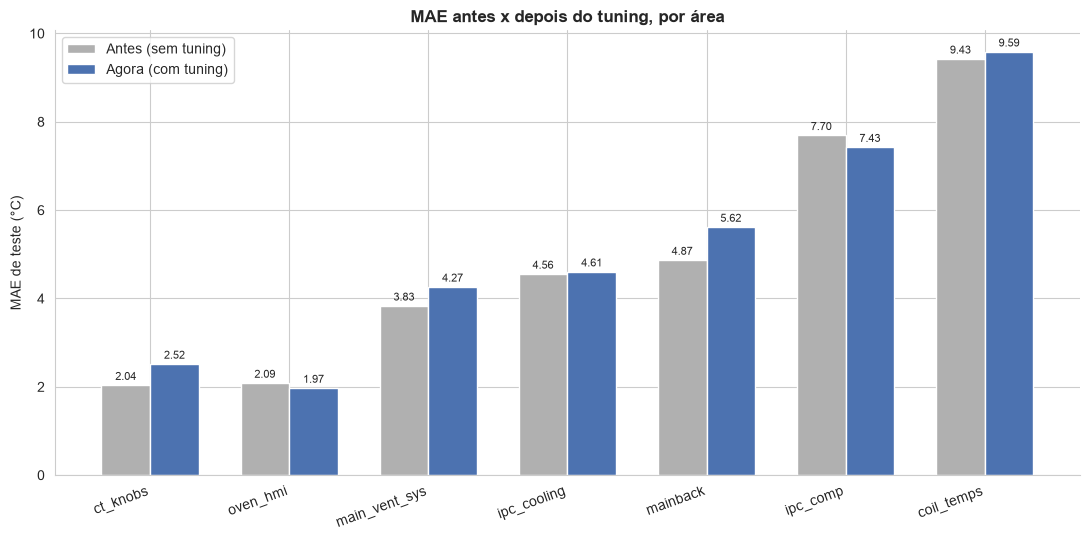

Barra azul (agora) mais alta que a cinza (antes) em 5 de 7 áreas — o tuning piorou o MAE de teste nessas.


In [11]:
# ============================================================
# GRÁFICO — MAE ANTES (sem tuning) x AGORA (com tuning), por área
# Complementa a tabela "O tuning valeu a pena?" da Célula 10 — usa a mesma
# `tuning`, sem recalcular nada.
# ============================================================
ordem_areas = tuning.sort_values("MAE_teste_padrao")["key_area"].tolist()
dados_grafico = tuning.set_index("key_area").loc[ordem_areas]

x = np.arange(len(ordem_areas))
largura = 0.35

fig, ax = plt.subplots(figsize=(11, 5.5))
barras_antes = ax.bar(x - largura / 2, dados_grafico["MAE_teste_padrao"], largura,
                       label="Antes (sem tuning)", color="#B0B0B0")
barras_agora = ax.bar(x + largura / 2, dados_grafico["MAE_teste_ajustado"], largura,
                       label="Agora (com tuning)", color="#4C72B0")

for barras in (barras_antes, barras_agora):
    ax.bar_label(barras, fmt="%.2f", padding=2, fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels([a.replace("_data.csv", "") for a in ordem_areas], rotation=20, ha="right")
ax.set_ylabel("MAE de teste (°C)")
ax.set_title("MAE antes x depois do tuning, por área", fontsize=12, fontweight="bold")
ax.legend()
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
plt.tight_layout()
plt.show()

pioraram = int((dados_grafico["MAE_teste_ajustado"] > dados_grafico["MAE_teste_padrao"]).sum())
print(f"Barra azul (agora) mais alta que a cinza (antes) em {pioraram} de {len(dados_grafico)} áreas "
      "— o tuning piorou o MAE de teste nessas.")

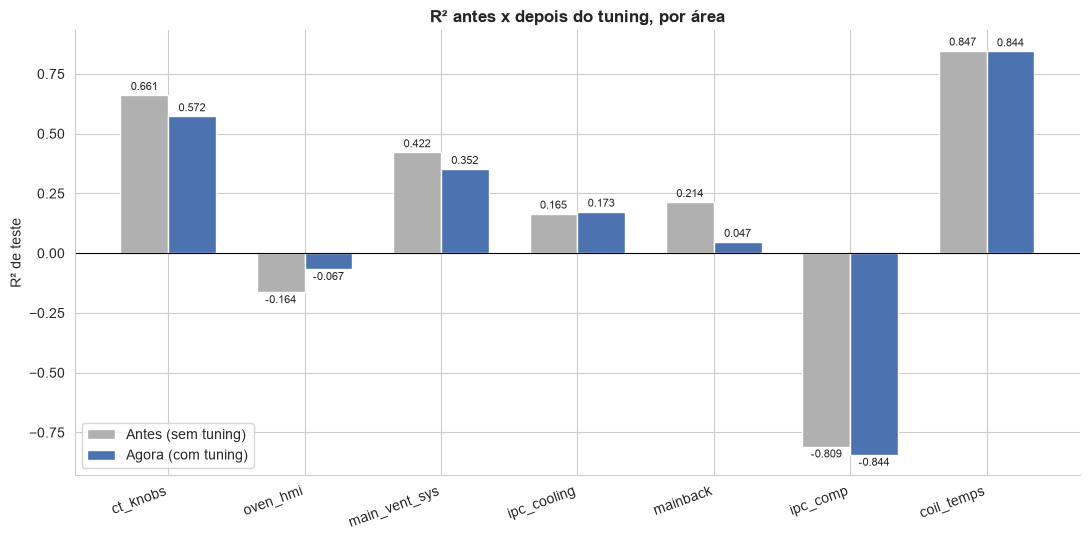

R² caiu (ficou pior) em 5 de 7 áreas com o tuning.


In [12]:
# ============================================================
# GRÁFICO — R² ANTES (sem tuning) x AGORA (com tuning), por área
# Mesma dupla de barras da MAE acima, agora para R² — usa a mesma `tuning`.
# ============================================================
dados_grafico_r2 = tuning.set_index("key_area").loc[ordem_areas]

x = np.arange(len(ordem_areas))
largura = 0.35

fig, ax = plt.subplots(figsize=(11, 5.5))
barras_antes_r2 = ax.bar(x - largura / 2, dados_grafico_r2["R2_teste_padrao"], largura,
                          label="Antes (sem tuning)", color="#B0B0B0")
barras_agora_r2 = ax.bar(x + largura / 2, dados_grafico_r2["R2_teste_ajustado"], largura,
                          label="Agora (com tuning)", color="#4C72B0")

for barras in (barras_antes_r2, barras_agora_r2):
    ax.bar_label(barras, fmt="%.3f", padding=2, fontsize=8)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels([a.replace("_data.csv", "") for a in ordem_areas], rotation=20, ha="right")
ax.set_ylabel("R² de teste")
ax.set_title("R² antes x depois do tuning, por área", fontsize=12, fontweight="bold")
ax.legend()
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
plt.tight_layout()
plt.show()

pioraram_r2 = int((dados_grafico_r2["R2_teste_ajustado"] < dados_grafico_r2["R2_teste_padrao"]).sum())
print(f"R² caiu (ficou pior) em {pioraram_r2} de {len(dados_grafico_r2)} áreas com o tuning.")

## 11. Efeito de remover `board_position` e `material_coil_support`

A Célula 5 já mostra, para a área carregada na Célula 2, que `board_position`
(0,011) e `material_coil_support` (0,009) têm importância bem menor que as
outras cinco variáveis. Isso ecoa a hipótese **H2** (Seção 4.2.4 da
documentação), que recomendara retirar variáveis redundantes do modelo — o
Gradient Boosting manteve as sete de propósito, registrando a remoção como um
"teste objetivo para a Seção 4.4" em vez de assumi-la sem medir.

Esta célula é esse teste, para o Random Forest e nas sete áreas: confirma que
a baixa importância se repete fora da área única, depois treina o mesmo
modelo (mesmos hiperparâmetros já escolhidos na Célula 10 — **não** repete o
Grid Search, para isolar o efeito da remoção de variáveis do ruído do tuning
já discutido) com e sem as duas variáveis, e compara o MAE de teste.

Requer ter rodado a Célula 7 (`INSUMOS_LOTE`, com o modelo e os hiperparâmetros
de cada área).

In [13]:
# ============================================================
# CÉLULA 11 — EFEITO DE REMOVER board_position E material_coil_support
# Reusa os hiperparâmetros já escolhidos por área (Célula 10); não repete o
# Grid Search, para que a comparação isole o efeito das variáveis, e não do
# ruído do tuning já discutido.
# ============================================================
VARIAVEIS_BAIXA_IMPORTANCIA = ["board_position", "material_coil_support"]

print("=" * 100)
print("IMPORTÂNCIA DAS VARIÁVEIS COM O MODELO COMPLETO (7 variáveis), POR ÁREA")
print("=" * 100)
importancias_completo = pd.DataFrame({
    insumo["nome_area"]: pd.Series(insumo["modelo"].feature_importances_, index=VARIAVEIS_INDEPENDENTES)
    for insumo in INSUMOS_LOTE
}).T
print(importancias_completo.round(4).to_string())
print(f"\nMédia entre as sete áreas, da mais para a menos importante:\n"
      f"{importancias_completo.mean().sort_values(ascending=False).round(4).to_string()}")


def treinar_com_variaveis(insumo, variaveis):
    """Retreina com os MESMOS hiperparâmetros já escolhidos, só mudando as colunas de X."""
    params = insumo["busca"].best_params_
    modelo = RandomForestRegressor(random_state=SEMENTE, n_jobs=-1, **params)
    modelo.fit(insumo["X_tr"][variaveis], insumo["Y_tr"])
    pred_teste = modelo.predict(insumo["X_te"][variaveis])
    mae = mean_absolute_error(insumo["Y_te"], pred_teste)
    r2 = r2_score(insumo["Y_te"], pred_teste)
    return modelo, mae, r2


VARIAVEIS_REDUZIDAS = [v for v in VARIAVEIS_INDEPENDENTES if v not in VARIAVEIS_BAIXA_IMPORTANCIA]

linhas, modelos_reduzidos = [], {}
for insumo in INSUMOS_LOTE:
    mae_completo = mean_absolute_error(insumo["Y_te"], insumo["previsoes_teste"])
    r2_completo = r2_score(insumo["Y_te"], insumo["previsoes_teste"])
    modelo_reduzido, mae_reduzido, r2_reduzido = treinar_com_variaveis(insumo, VARIAVEIS_REDUZIDAS)
    modelos_reduzidos[insumo["nome_area"]] = modelo_reduzido
    linhas.append({
        "key_area": insumo["nome_area"],
        "MAE_7_variaveis": mae_completo,
        "MAE_5_variaveis": mae_reduzido,
        "diferenca_C": mae_reduzido - mae_completo,
        "R2_7_variaveis": r2_completo,
        "R2_5_variaveis": r2_reduzido,
    })

comparativo_variaveis = pd.DataFrame(linhas)
print("\n" + "=" * 100)
print(f"REMOVER {VARIAVEIS_BAIXA_IMPORTANCIA} — MAE de teste, mesmos hiperparâmetros de cada área")
print("=" * 100)
print(comparativo_variaveis.round(3).to_string(index=False))
print(f"\nMelhorou (MAE menor) em {int((comparativo_variaveis['diferenca_C'] < 0).sum())} de "
      f"{len(comparativo_variaveis)} áreas — diferença média: "
      f"{comparativo_variaveis['diferenca_C'].mean():+.3f} °C")

print("\n" + "=" * 100)
print("IMPORTÂNCIA DAS VARIÁVEIS QUE SOBRARAM (5 variáveis), POR ÁREA")
print("=" * 100)
importancias_reduzido = pd.DataFrame({
    area: pd.Series(modelo.feature_importances_, index=VARIAVEIS_REDUZIDAS)
    for area, modelo in modelos_reduzidos.items()
}).T
print(importancias_reduzido.round(4).to_string())
print(f"\nMédia entre as sete áreas, da mais para a menos importante:\n"
      f"{importancias_reduzido.mean().sort_values(ascending=False).round(4).to_string()}")

IMPORTÂNCIA DAS VARIÁVEIS COM O MODELO COMPLETO (7 variáveis), POR ÁREA


                        blower_direction  housing  board_position  run_case  losses  deflector_hole  material_coil_support
mainback_data.csv                 0.1274   0.1220          0.0980    0.3444  0.1853          0.1093                 0.0136
coil_temps_data.csv               0.0104   0.0213          0.0035    0.8009  0.0435          0.0165                 0.1039
main_vent_sys_data.csv            0.2461   0.1146          0.0113    0.2112  0.2217          0.1862                 0.0088
ct_knobs_data.csv                 0.1025   0.1684          0.0236    0.3210  0.2446          0.1151                 0.0248
ipc_comp_data.csv                 0.0000   0.0458          0.0000    0.4990  0.4315          0.0000                 0.0237
ipc_cooling_data.csv              0.0272   0.0641          0.0021    0.2109  0.5298          0.1334                 0.0326
oven_hmi_data.csv                 0.2355   0.0714          0.1323    0.2642  0.0723          0.2234                 0.0008

Média entre as 


REMOVER ['board_position', 'material_coil_support'] — MAE de teste, mesmos hiperparâmetros de cada área
              key_area  MAE_7_variaveis  MAE_5_variaveis  diferenca_C  R2_7_variaveis  R2_5_variaveis
     mainback_data.csv            5.619            5.792        0.172           0.047          -0.089
   coil_temps_data.csv            9.587            8.009       -1.579           0.844           0.904
main_vent_sys_data.csv            4.265            3.967       -0.298           0.352           0.472
     ct_knobs_data.csv            2.519            2.380       -0.140           0.572           0.604
     ipc_comp_data.csv            7.428            7.430        0.003          -0.844          -0.853
  ipc_cooling_data.csv            4.608            4.672        0.064           0.173           0.168
     oven_hmi_data.csv            1.973            1.914       -0.059          -0.067           0.057

Melhorou (MAE menor) em 4 de 7 áreas — diferença média: -0.262 °C

IMPORTÂNCIA

                        blower_direction  housing  run_case  losses  deflector_hole
mainback_data.csv                 0.1377   0.1084    0.4129  0.2236          0.1173
coil_temps_data.csv               0.0121   0.0352    0.8592  0.0733          0.0202
main_vent_sys_data.csv            0.2037   0.0971    0.2404  0.2744          0.1843
ct_knobs_data.csv                 0.1052   0.1778    0.3480  0.2521          0.1168
ipc_comp_data.csv                 0.0000   0.0432    0.5061  0.4507          0.0000
ipc_cooling_data.csv              0.0277   0.0680    0.2201  0.5451          0.1391
oven_hmi_data.csv                 0.2402   0.1232    0.3009  0.0984          0.2373

Média entre as sete áreas, da mais para a menos importante:
run_case            0.4125
losses              0.2740
deflector_hole      0.1164
blower_direction    0.1038
housing             0.0933


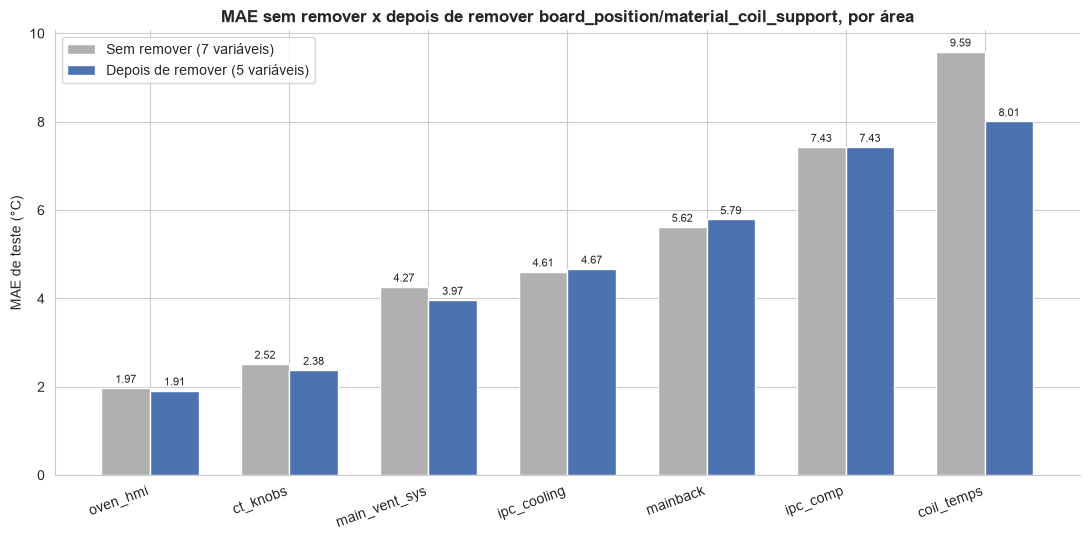

Barra azul (depois de remover) mais baixa que a cinza (sem remover) em 4 de 7 áreas — a remoção ajudou nessas.


In [14]:
# ============================================================
# GRÁFICO — MAE COM 7 VARIÁVEIS x SEM board_position/material_coil_support
# Complementa a tabela da Célula 11 — usa `comparativo_variaveis`, sem
# recalcular nada.
# ============================================================
ordem_areas_var = comparativo_variaveis.sort_values("MAE_7_variaveis")["key_area"].tolist()
dados_grafico_var = comparativo_variaveis.set_index("key_area").loc[ordem_areas_var]

x = np.arange(len(ordem_areas_var))
largura = 0.35

fig, ax = plt.subplots(figsize=(11, 5.5))
barras_sem_remover = ax.bar(x - largura / 2, dados_grafico_var["MAE_7_variaveis"], largura,
                             label="Sem remover (7 variáveis)", color="#B0B0B0")
barras_depois = ax.bar(x + largura / 2, dados_grafico_var["MAE_5_variaveis"], largura,
                        label="Depois de remover (5 variáveis)", color="#4C72B0")

for barras in (barras_sem_remover, barras_depois):
    ax.bar_label(barras, fmt="%.2f", padding=2, fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels([a.replace("_data.csv", "") for a in ordem_areas_var], rotation=20, ha="right")
ax.set_ylabel("MAE de teste (°C)")
ax.set_title("MAE sem remover x depois de remover board_position/material_coil_support, por área",
             fontsize=12, fontweight="bold")
ax.legend()
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
plt.tight_layout()
plt.show()

melhoraram = int((dados_grafico_var["MAE_5_variaveis"] < dados_grafico_var["MAE_7_variaveis"]).sum())
print(f"Barra azul (depois de remover) mais baixa que a cinza (sem remover) em "
      f"{melhoraram} de {len(dados_grafico_var)} áreas — a remoção ajudou nessas.")

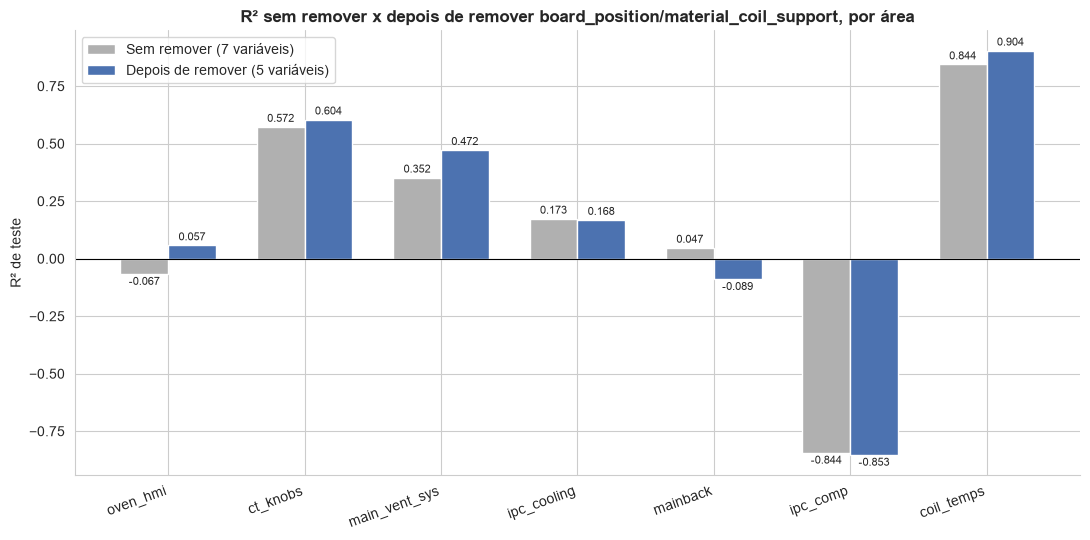

R² melhorou (subiu) em 4 de 7 áreas ao remover as variáveis.


In [15]:
# ============================================================
# GRÁFICO — R² COM 7 VARIÁVEIS x SEM board_position/material_coil_support
# Mesma dupla de barras da MAE acima, agora para R² — usa a mesma
# `comparativo_variaveis`.
# ============================================================
dados_grafico_var_r2 = comparativo_variaveis.set_index("key_area").loc[ordem_areas_var]

x = np.arange(len(ordem_areas_var))
largura = 0.35

fig, ax = plt.subplots(figsize=(11, 5.5))
barras_sem_remover_r2 = ax.bar(x - largura / 2, dados_grafico_var_r2["R2_7_variaveis"], largura,
                                label="Sem remover (7 variáveis)", color="#B0B0B0")
barras_depois_r2 = ax.bar(x + largura / 2, dados_grafico_var_r2["R2_5_variaveis"], largura,
                           label="Depois de remover (5 variáveis)", color="#4C72B0")

for barras in (barras_sem_remover_r2, barras_depois_r2):
    ax.bar_label(barras, fmt="%.3f", padding=2, fontsize=8)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels([a.replace("_data.csv", "") for a in ordem_areas_var], rotation=20, ha="right")
ax.set_ylabel("R² de teste")
ax.set_title("R² sem remover x depois de remover board_position/material_coil_support, por área",
             fontsize=12, fontweight="bold")
ax.legend()
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
plt.tight_layout()
plt.show()

melhoraram_var_r2 = int((dados_grafico_var_r2["R2_5_variaveis"] > dados_grafico_var_r2["R2_7_variaveis"]).sum())
print(f"R² melhorou (subiu) em {melhoraram_var_r2} de {len(dados_grafico_var_r2)} áreas ao remover as variáveis.")

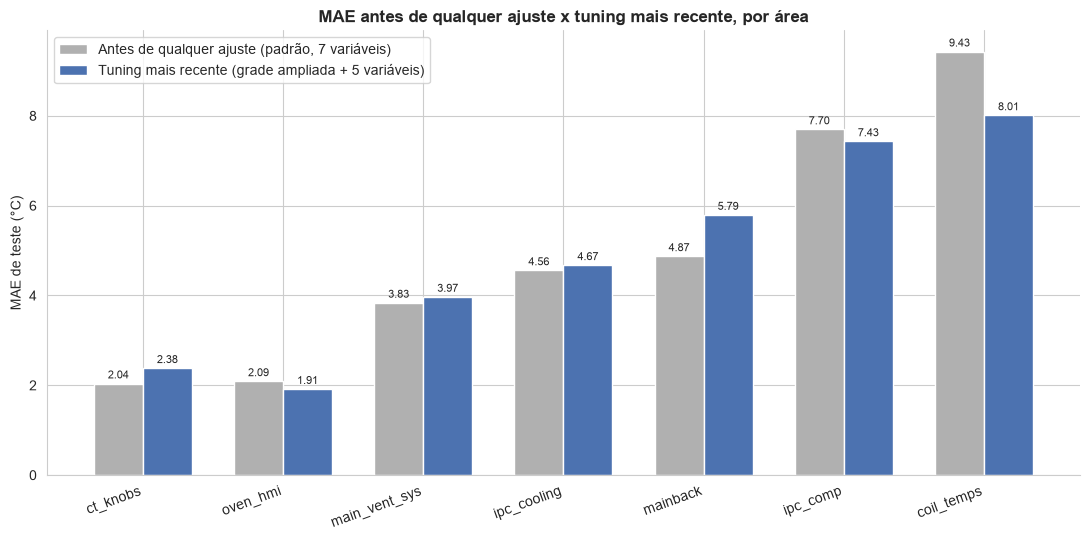

Barra azul (tuning mais recente) mais baixa que a cinza (antes de qualquer ajuste) em 3 de 7 áreas.

              key_area  MAE_teste_padrao  MAE_tuning_recente  diferenca_C
     mainback_data.csv             4.871               5.792        0.921
   coil_temps_data.csv             9.428               8.009       -1.419
main_vent_sys_data.csv             3.835               3.967        0.132
     ct_knobs_data.csv             2.038               2.380        0.342
     ipc_comp_data.csv             7.696               7.430       -0.265
  ipc_cooling_data.csv             4.557               4.672        0.115
     oven_hmi_data.csv             2.087               1.914       -0.173


In [16]:
# ============================================================
# GRÁFICO — MAE ANTES DE QUALQUER AJUSTE x TUNING MAIS RECENTE
# (hiperparâmetros ajustados na grade ampliada + as 2 variáveis de menor
# importância removidas). Junta `tuning` (Célula 10) com
# `comparativo_variaveis` (Célula 11) por key_area — não recalcula nada.
# ============================================================
comparativo_final = tuning[["key_area", "MAE_teste_padrao"]].merge(
    comparativo_variaveis[["key_area", "MAE_5_variaveis"]], on="key_area"
).rename(columns={"MAE_5_variaveis": "MAE_tuning_recente"})

ordem_areas_final = comparativo_final.sort_values("MAE_teste_padrao")["key_area"].tolist()
dados_grafico_final = comparativo_final.set_index("key_area").loc[ordem_areas_final]

x = np.arange(len(ordem_areas_final))
largura = 0.35

fig, ax = plt.subplots(figsize=(11, 5.5))
barras_antes = ax.bar(x - largura / 2, dados_grafico_final["MAE_teste_padrao"], largura,
                       label="Antes de qualquer ajuste (padrão, 7 variáveis)", color="#B0B0B0")
barras_recente = ax.bar(x + largura / 2, dados_grafico_final["MAE_tuning_recente"], largura,
                         label="Tuning mais recente (grade ampliada + 5 variáveis)", color="#4C72B0")

for barras in (barras_antes, barras_recente):
    ax.bar_label(barras, fmt="%.2f", padding=2, fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels([a.replace("_data.csv", "") for a in ordem_areas_final], rotation=20, ha="right")
ax.set_ylabel("MAE de teste (°C)")
ax.set_title("MAE antes de qualquer ajuste x tuning mais recente, por área",
             fontsize=12, fontweight="bold")
ax.legend()
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
plt.tight_layout()
plt.show()

melhoraram_final = int((dados_grafico_final["MAE_tuning_recente"] < dados_grafico_final["MAE_teste_padrao"]).sum())
print(f"Barra azul (tuning mais recente) mais baixa que a cinza (antes de qualquer ajuste) em "
      f"{melhoraram_final} de {len(dados_grafico_final)} áreas.")
print("\n" + comparativo_final.assign(
    diferenca_C=lambda d: d["MAE_tuning_recente"] - d["MAE_teste_padrao"]
).round(3).to_string(index=False))

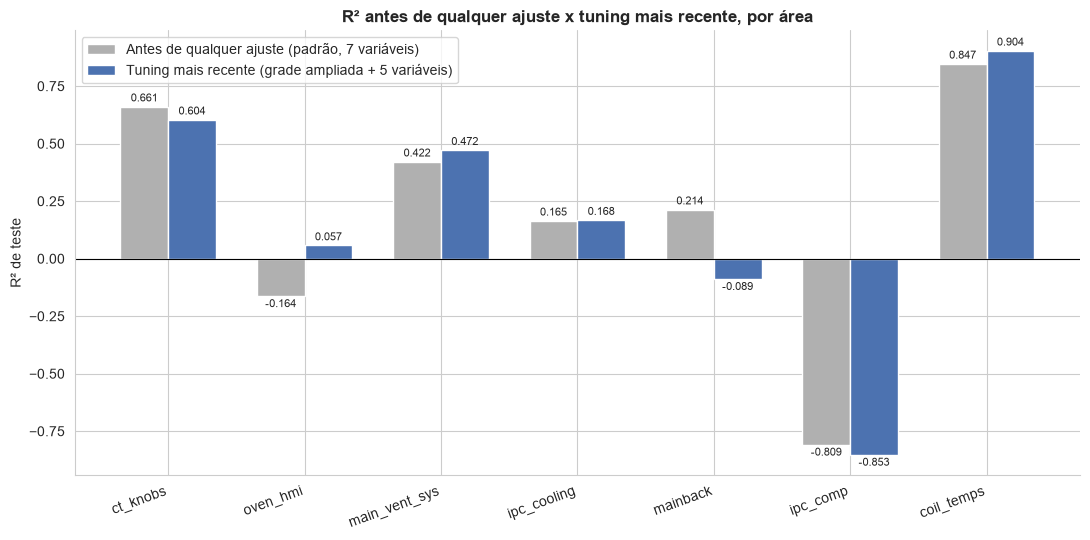

R² melhorou (subiu) em 4 de 7 áreas no pacote completo (tuning + remoção) vs. o modelo mais simples.

              key_area  R2_teste_padrao  R2_tuning_recente  diferenca
     mainback_data.csv           0.2136            -0.0891    -0.3027
   coil_temps_data.csv           0.8471             0.9040     0.0569
main_vent_sys_data.csv           0.4218             0.4718     0.0501
     ct_knobs_data.csv           0.6612             0.6043    -0.0569
     ipc_comp_data.csv          -0.8091            -0.8530    -0.0438
  ipc_cooling_data.csv           0.1650             0.1678     0.0028
     oven_hmi_data.csv          -0.1635             0.0573     0.2209


In [17]:
# ============================================================
# GRÁFICO — R² ANTES DE QUALQUER AJUSTE x TUNING MAIS RECENTE
# Mesma dupla de barras da MAE acima, agora para R² — junta `tuning` com
# `comparativo_variaveis` por key_area, igual à célula da MAE.
# ============================================================
comparativo_final_r2 = tuning[["key_area", "R2_teste_padrao"]].merge(
    comparativo_variaveis[["key_area", "R2_5_variaveis"]], on="key_area"
).rename(columns={"R2_5_variaveis": "R2_tuning_recente"})

dados_grafico_final_r2 = comparativo_final_r2.set_index("key_area").loc[ordem_areas_final]

x = np.arange(len(ordem_areas_final))
largura = 0.35

fig, ax = plt.subplots(figsize=(11, 5.5))
barras_antes_final_r2 = ax.bar(x - largura / 2, dados_grafico_final_r2["R2_teste_padrao"], largura,
                                label="Antes de qualquer ajuste (padrão, 7 variáveis)", color="#B0B0B0")
barras_recente_r2 = ax.bar(x + largura / 2, dados_grafico_final_r2["R2_tuning_recente"], largura,
                            label="Tuning mais recente (grade ampliada + 5 variáveis)", color="#4C72B0")

for barras in (barras_antes_final_r2, barras_recente_r2):
    ax.bar_label(barras, fmt="%.3f", padding=2, fontsize=8)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels([a.replace("_data.csv", "") for a in ordem_areas_final], rotation=20, ha="right")
ax.set_ylabel("R² de teste")
ax.set_title("R² antes de qualquer ajuste x tuning mais recente, por área",
             fontsize=12, fontweight="bold")
ax.legend()
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
plt.tight_layout()
plt.show()

melhoraram_final_r2 = int(
    (dados_grafico_final_r2["R2_tuning_recente"] > dados_grafico_final_r2["R2_teste_padrao"]).sum()
)
print(f"R² melhorou (subiu) em {melhoraram_final_r2} de {len(dados_grafico_final_r2)} áreas "
      "no pacote completo (tuning + remoção) vs. o modelo mais simples.")
print("\n" + comparativo_final_r2.assign(
    diferenca=lambda d: d["R2_tuning_recente"] - d["R2_teste_padrao"]
).round(4).to_string(index=False))